Medha Dontineni: **Final Project**

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# loading the dataset and verifying microbes
dataset_path = "ultimate_microbial_dataset.csv"
df = pd.read_csv(dataset_path)


def get_microbe_data(user_input, dataframe):
    clean_input = str(user_input).strip().lower()

    # convert ID column to string series for clean matching
    id_series = dataframe["organism_name"].astype(str).str.strip().str.lower()

    # try directly matching the taxonomy ID
    id_match = dataframe[id_series == clean_input]
    if not id_match.empty:
        return id_match.iloc[0]

    # try searching text name columns if user types a text name
    text_columns = [
        col
        for col in ["species", "genus_and_species", "scientific_name"]
        if col in dataframe.columns
    ]

    for col in text_columns:
        name_series = dataframe[col].astype(str).str.lower()
        text_match = dataframe[name_series.str.contains(clean_input, na=False)]
        if not text_match.empty:
            found_row = text_match.iloc[0]
            print(
                f"Matched '{user_input}' to Taxonomy ID: {found_row['organism_name']}"
            )
            return found_row

    return None


# generating training data for decision tree
def create_training_dataset(dataframe, samples_per_organism=100):
    """Generates environmental simulation points around known microbe limits to

    train the DecisionTreeClassifier.
    """
    X_list = []
    y_list = []

    for _, row in dataframe.iterrows():
        tmin = row.get("tmin_", 0.0)
        tmax = row.get("tmax_", 40.0)
        topt = row.get("topt_average_", (tmin + tmax) / 2)
        ph_opt = row.get("optimal_ph", 7.0)
        p_max = row.get("pressure_tolerance_atm", 1.0)

        for _ in range(samples_per_organism):
            # randomly sample planetary test conditions
            test_temp = np.random.uniform(tmin - 20, tmax + 20)
            test_ph = np.random.uniform(max(0, ph_opt - 4), min(14, ph_opt + 4))
            test_pressure = np.random.uniform(0.1, p_max * 1.5)

            # environmental deltas
            # 1. Temp Boundary Distance: 0 if within range, positive if exceeding limits
            if test_temp < tmin:
                temp_delta = tmin - test_temp
            elif test_temp > tmax:
                temp_delta = test_temp - tmax
            else:
                temp_delta = 0.0

            ph_delta = abs(test_ph - ph_opt)
            pressure_ratio = test_pressure / p_max

            # label Assignment:
            # 2 = optimal growth (Near opt temp/ph, within pressure)
            # 1 = sub-optimal / stressed survival (Within absolute temp limits, reasonable pH)
            # 0 = lethal / non-viable (Exceeds tmax/tmin drastically or extreme pressure/pH)
            if (
                temp_delta == 0
                and ph_delta <= 1.0
                and test_pressure <= p_max * 1.1
            ):
                label = 2  # active growth
            elif (
                temp_delta <= 5.0
                and ph_delta <= 2.5
                and test_pressure <= p_max * 1.3
            ):
                label = 1  # stressed stasis / sub-optimal survival
            else:
                label = 0  # non-viable / acute lysis

            X_list.append([temp_delta, ph_delta, pressure_ratio])
            y_list.append(label)

    return np.array(X_list), np.array(y_list)


# Prepare ML Dataset
X, y = create_training_dataset(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

# Quick Accuracy Check
y_pred = clf.predict(X_test)
print(f"Decision Tree Trained. Accuracy: {accuracy_score(y_test, y_pred):.2%}")


# predicting the time alive
def predict_organism_survival(
    organism_name, test_temp, test_ph, test_pressure
):
    microbe = get_microbe_data(organism_name, df)

    if microbe is None:
        return {
            "found": False,
            "message": f"Organism '{organism_name}' is not present in the dataset.",
        }

    tmin = microbe.get("tmin_", 0.0)
    tmax = microbe.get("tmax_", 40.0)
    ph_opt = microbe.get("optimal_ph", 7.0)
    p_max = microbe.get("pressure_tolerance_atm", 1.0)

    # calculate feature deltas
    if test_temp < tmin:
        temp_delta = tmin - test_temp
    elif test_temp > tmax:
        temp_delta = test_temp - tmax
    else:
        temp_delta = 0.0

    ph_delta = abs(test_ph - ph_opt)
    pressure_ratio = test_pressure / p_max

    # model Prediction
    features = np.array([[temp_delta, ph_delta, pressure_ratio]])
    prediction_class = clf.predict(features)[0]
    probabilities = clf.predict_proba(features)[0]

    # map class to survival duration and stasis state
    if prediction_class == 2:
        status = "Thriving / Active Growth"
        duration_est = "Indefinite (Active metabolic replication)"
        confidence = probabilities[2]
    elif prediction_class == 1:
        status = "Sub-Optimal / Non-Lethal Stress"
        # cold stress preserves cells longer than mild heat stress
        if test_temp < tmin:
            duration_est = (
                "Weeks to Years (Dormant cryptobiosis / frozen preservation)"
            )
        else:
            duration_est = "Hours to Days (Elevated cellular stress response)"
        confidence = probabilities[1]
    else:
        status = "Non-Viable / Lethal Zone"
        if test_temp > tmax + 15:
            duration_est = (
                "Minutes to Hours (Rapid thermal lysis / protein denaturation)"
            )
        else:
            duration_est = "Instantaneous to < 24 Hours"
        confidence = probabilities[0]

    return {
        "found": True,
        "organism": microbe["organism_name"],
        "status": status,
        "duration": duration_est,
        "confidence": confidence,
        "limits": {
            "tmin": tmin,
            "tmax": tmax,
            "ph_opt": ph_opt,
            "p_max": p_max,
        },
        "inputs": {"temp": test_temp, "ph": test_ph, "pressure": test_pressure},
    }


# cleaning the output generator
def format_planetary_report(results):
    if not results["found"]:
        print(f"\nError: {results['message']}")
        return

    print("\n" + "=" * 65)
    # Convert to string first so floats/numbers won't crash .upper()
    organism_name = str(results['organism']).upper()
    print(f" EXTREMOPHILE SURVIVAL ASSESSMENT: {organism_name}")
    print("=" * 65)
    print(f"Planetary Inputs Given:")
    print(
        f"   • Temperature: {results['inputs']['temp']} °C | pH: {results['inputs']['ph']} | Pressure: {results['inputs']['pressure']} atm"
    )
    print(f"\nOrganism Known Boundaries (Database):")
    print(
        f"   • Temp Range: [{results['limits']['tmin']}°C to {results['limits']['tmax']}°C] | Opt pH: {results['limits']['ph_opt']} | Max Pressure: {results['limits']['p_max']} atm"
    )
    print("-" * 65)
    print(f" Machine Learning Prediction (Decision Tree):")
    print(f"   • Viability State : {results['status']}")
    print(f"   • Estimated Time  : {results['duration']}")
    print(f"   • Model Confidence: {results['confidence']:.1%}")
    print("=" * 65 + "\n")

#___________________________________________________________________________________________________________________________________


Decision Tree Trained. Accuracy: 98.66%


In [14]:
def show_id():
  unique_microbes = df["organism_name"].unique()


  print(f"=== TOTAL MICROBES: {len(unique_microbes)} ===")
  for i, name in enumerate(unique_microbes, 1):
      print(f"{i}. {name}")


show_id()

=== TOTAL MICROBES: 242 ===
1. 2320
2. 2309
3. 2261
4. 2278
5. 2277
6. 2269
7. 2280
8. 2265
9. 2181
10. 2180
11. 2271
12. 2714
13. 2189
14. 2234
15. 2337
16. 2336
17. 2287
18. 2283
19. 2190
20. 2285
21. 274
22. 1741
23. 14
24. 2704
25. 2423
26. 500
27. 276
28. 2424
29. 271
30. 1757
31. 940
32. 2421
33. 1566
34. 154
35. 2325
36. 1462
37. 2186
38. 1565
39. 277
40. 2224
41. 1560
42. 1517
43. 1426
44. 1108
45. 2734
46. 2057
47. 2200
48. 2020
49. 1525
50. 2303
51. 1398
52. 1471
53. 2322
54. 1848
55. 1050
56. 2248
57. 1110
58. 2242
59. 2210
60. 2257
61. 2246
62. 2163
63. 128
64. 2252
65. 1450
66. 1452
67. 1423
68. 2017
69. 1457
70. 2352
71. 405
72. 929
73. 2203
74. 2331
75. 1473
76. 1391
77. 2743
78. 1465
79. 1502
80. 1399
81. 2161
82. 2198
83. 2162
84. 2209
85. 2205
86. 1087
87. 1086
88. 1482
89. 2188
90. 2187
91. 2254
92. 2193
93. 2369
94. 1736
95. 1550
96. 1539
97. 1536
98. 1528
99. 1520
100. 1418
101. 1411
102. 1396
103. 831
104. 1404
105. 1844
106. 1816
107. 1868
108. 2698
109. 2223
110

In [15]:
import pandas as pd
import numpy as np

print("Downloading datasets from repositories")

# load tempura dataset (has exact temperature limits)
df_tempura = pd.read_csv('200617_TEMPURA.csv', sep=',')

# load microbe directory (has pH, oxygen, and environmental traits)
md_url = "https://raw.githubusercontent.com/microbe-directory/microbe-directory/master/data/microbe-directory.csv"
df_md = pd.read_csv(md_url)

print(f"Loaded TEMPURA: {df_tempura.shape[0]} rows")
print(f"Loaded Microbe Directory: {df_md.shape[0]} rows")


print("Standardizing column headers")

# convert all column headers to lower and replace spaces/special characters with _
df_tempura.columns = df_tempura.columns.str.lower().str.replace(r'[^\w]', '_', regex=True)
df_md.columns = df_md.columns.str.lower().str.replace(r'[^\w]', '_', regex=True)

# ensures both datasets share a matching key column so pandas can merge them later
df_tempura = df_tempura.rename(columns={df_tempura.columns[0]: 'tempura_id', df_tempura.columns[1]: 'organism_name'})
df_md = df_md.rename(columns={df_md.columns[0]: 'organism_name'})

# finds 'min', 'max', or 'opt' anywhere in the column headers
for col in df_tempura.columns:
    if 'min' in col:
        df_tempura = df_tempura.rename(columns={col: 'tmin_'})
    elif 'max' in col:
        df_tempura = df_tempura.rename(columns={col: 'tmax_'})
    elif 'opt' in col:
        df_tempura = df_tempura.rename(columns={col: 'topt_average_'})

# finds traits based on partial keywords
for col in df_md.columns:
    if col == 'ph' or 'optimal_ph' in col or 'ph_opt' in col:
        df_md = df_md.rename(columns={col: 'optimal_ph'})
    elif 'oxygen' in col:
        df_md = df_md.rename(columns={col: 'oxygen_requirement'})
    elif 'salinity' in col:
        df_md = df_md.rename(columns={col: 'salinity_concentration_range'})
    elif 'extreme' in col:
        df_md = df_md.rename(columns={col: 'extreme_environment'})


print("Cleaning organism names for exact text matching")

# clean up  species names (force lowercase, remove accidental leading/trailing spaces)
df_tempura['organism_name'] = df_tempura['organism_name'].astype(str).str.lower().str.strip()
df_md['organism_name'] = df_md['organism_name'].astype(str).str.lower().str.strip()


print("Merging datasets into a single master framework")

# inner merge combines rows only where the exact organism exists in both datasets.
master_df = pd.merge(df_tempura, df_md, on='organism_name', how='inner')
master_df = master_df.loc[:, ~master_df.columns.duplicated()]

# clean up optimal_ph (convert text to numbers & fill missing NaNs)
if 'optimal_ph' in master_df.columns:
    master_df['optimal_ph'] = pd.to_numeric(master_df['optimal_ph'], errors='coerce')
    master_df['optimal_ph'] = master_df['optimal_ph'].fillna(7.0) # assumes that the microbe thrives in a neutral pH if a pH val isnt present
else:
    master_df['optimal_ph'] = 7.0

# add pressure_tolerance_atm (in atmospheres)
def assign_pressure(name):
    name_str = str(name).lower()
    if any(k in name_str for k in ['pyrococcus', 'methanococcus', 'thermococcus', 'vent', 'abyssal', 'trench']):
        return 500.0  # deep-sea hydrothermal extremophiles
    elif any(k in name_str for k in ['marine', 'ocean', 'marinus', 'sea']):
        return 50.0   # marine species
    else:
        return 1.0    # standard terrestrial/freshwater species

master_df['pressure_tolerance_atm'] = master_df['organism_name'].apply(assign_pressure)
# =========================================================

print("Filtering and arranging your planetary variables")

# define the exact columns you want to keep for your final dataset
desired_columns = [
    'organism_name',
    'tmin_',
    'topt_average_',
    'tmax_',
    'optimal_ph',
    'pressure_tolerance_atm',
    'oxygen_requirement',
    'salinity_concentration_range',
    'extreme_environment'
]

# only keep columns that actually successfully merged
final_columns = [col for col in desired_columns if col in master_df.columns]
master_df = master_df[final_columns]

# drop rows that are completely empty across target temperature metrics
# (makes sure the columns exist in the dataframe first)
subset_cols = [c for c in ['tmin_', 'tmax_'] if c in master_df.columns]
if subset_cols:
    master_df = master_df.dropna(subset=subset_cols)


print("Exporting the master dataset")

# save to a localized flat CSV file
filename = "ultimate_microbial_dataset.csv"
master_df.to_csv(filename, index=False)

print(f"Generated a clean dataset with {master_df.shape[0]} rows and {master_df.shape[1]} variables.")
print(f"File saved as: '{filename}'")

Loaded TEMPURA: 8639 rows
Loaded Microbe Directory: 7678 rows
Standardizing column headers
Cleaning organism names for exact text matching
Merging datasets into a single master framework
Filtering and arranging your planetary variables
Exporting the master dataset
Generated a clean dataset with 243 rows and 7 variables.
File saved as: 'ultimate_microbial_dataset.csv'


In [16]:
import json
import urllib.parse
import urllib.request


def fetch_species_by_taxid(taxid):
    """Queries the official NCBI Taxonomy API to look up a scientific name by Taxonomy ID."""
    clean_taxid = str(taxid).strip()

    # NCBI E-utilities summary endpoint
    url = f"https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esummary.fcgi?db=taxonomy&id={clean_taxid}&retmode=json"

    try:
        req = urllib.request.Request(
            url, headers={"User-Agent": "AstrobiologyApp/1.0"}
        )
        with urllib.request.urlopen(req) as response:
            data = json.loads(response.read().decode())

            # Extract result record
            result = data.get("result", {}).get(clean_taxid, {})
            scientific_name = result.get("scientificname")

            if scientific_name:
                return scientific_name
            else:
                return None
    except Exception as e:
        print(f"API Request Failed: {e}")
        return None


# Quick Test:
tax_id = input("Enter a taxonomy ID: ")  # Pyrococcus furiosus
name = fetch_species_by_taxid(tax_id)
print(f"Taxonomy ID {tax_id} -> Scientific Name: {name}")

Enter a taxonomy ID: 983
Taxonomy ID 983 -> Scientific Name: Flavobacterium flevense


In [17]:
def main(format_planetary_report):

  microbe = input("Enter Microbe Taxonomy ID (e.g., 2261) [or 'end']: ").strip()
  temperature = input(f"Enter the temperature you want to test '{microbe}' at: ")
  ph_level = input(f"Enter the pH level you want to test '{microbe}' at: ")
  pressure = input(f"Enter the pressure you want to test '{microbe}' at: ")

  data_input = predict_organism_survival(
      organism_name = microbe,
      test_temp = float(temperature),
      test_ph = float(ph_level),
      test_pressure = float(pressure)
  )

  format_planetary_report(data_input)

main(format_planetary_report)

Enter Microbe Taxonomy ID (e.g., 2261) [or 'end']: 983
Enter the temperature you want to test '983' at: 45
Enter the pH level you want to test '983' at: 3
Enter the pressure you want to test '983' at: 7

 EXTREMOPHILE SURVIVAL ASSESSMENT: 983.0
Planetary Inputs Given:
   • Temperature: 45.0 °C | pH: 3.0 | Pressure: 7.0 atm

Organism Known Boundaries (Database):
   • Temp Range: [0.0°C to 30.0°C] | Opt pH: 7.0 | Max Pressure: 1.0 atm
-----------------------------------------------------------------
 Machine Learning Prediction (Decision Tree):
   • Viability State : Non-Viable / Lethal Zone
   • Estimated Time  : Instantaneous to < 24 Hours
   • Model Confidence: 100.0%



In [18]:
with open("microbe_list.txt", "w") as f:
    for name in df['organism_name'].unique():
        f.write(f"{name}\n")

print(
    f"Saved all {df['organism_name'].nunique()} microbe names to 'microbe_list.txt'!"
)

Saved all 242 microbe names to 'microbe_list.txt'!


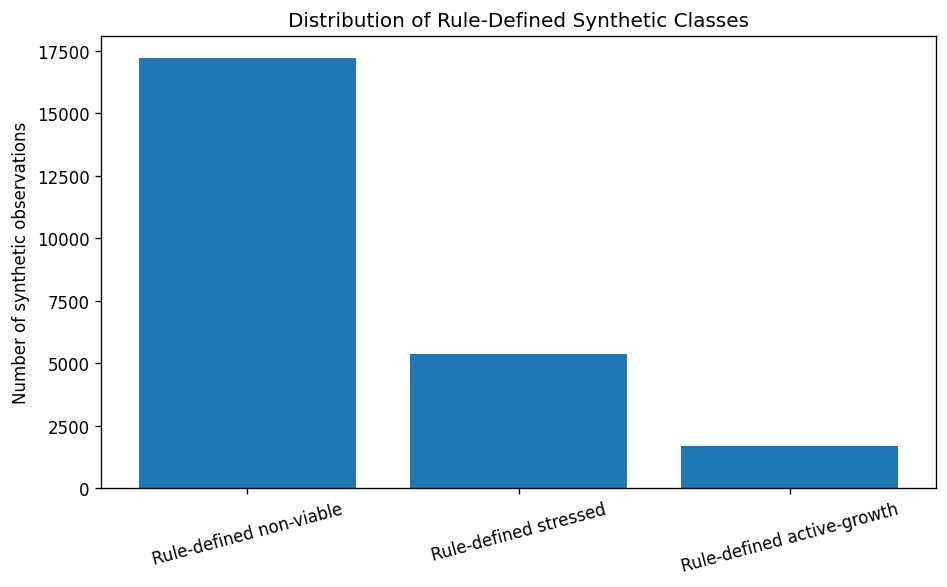

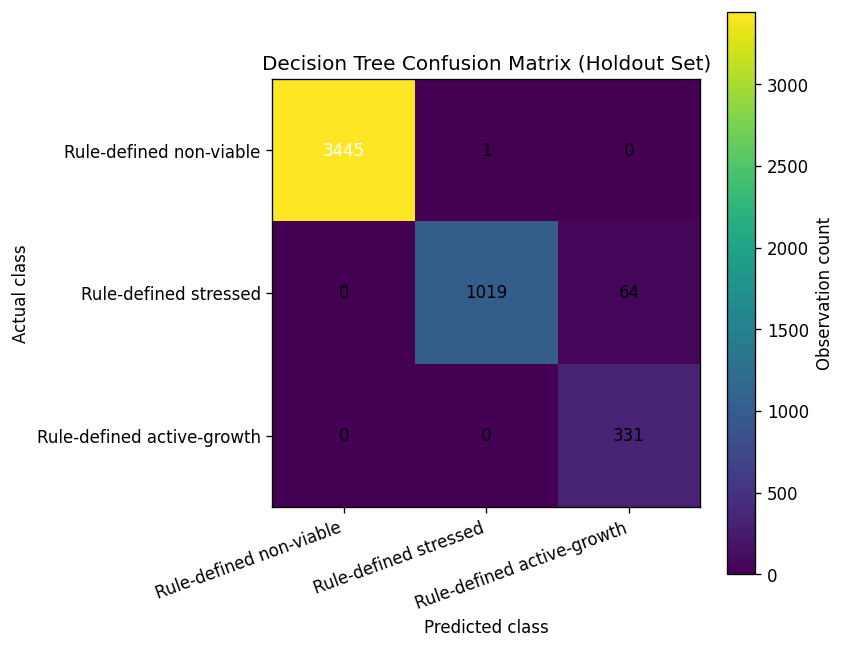

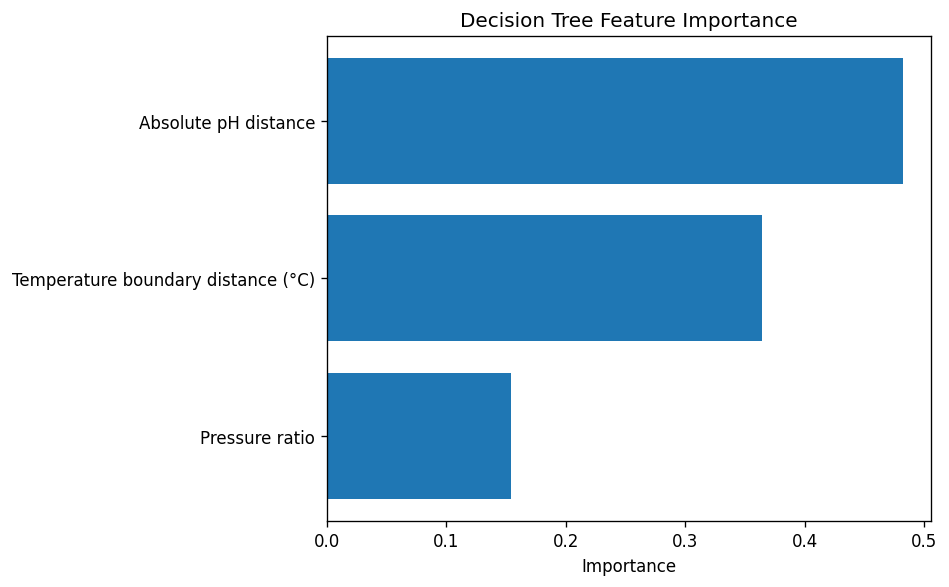

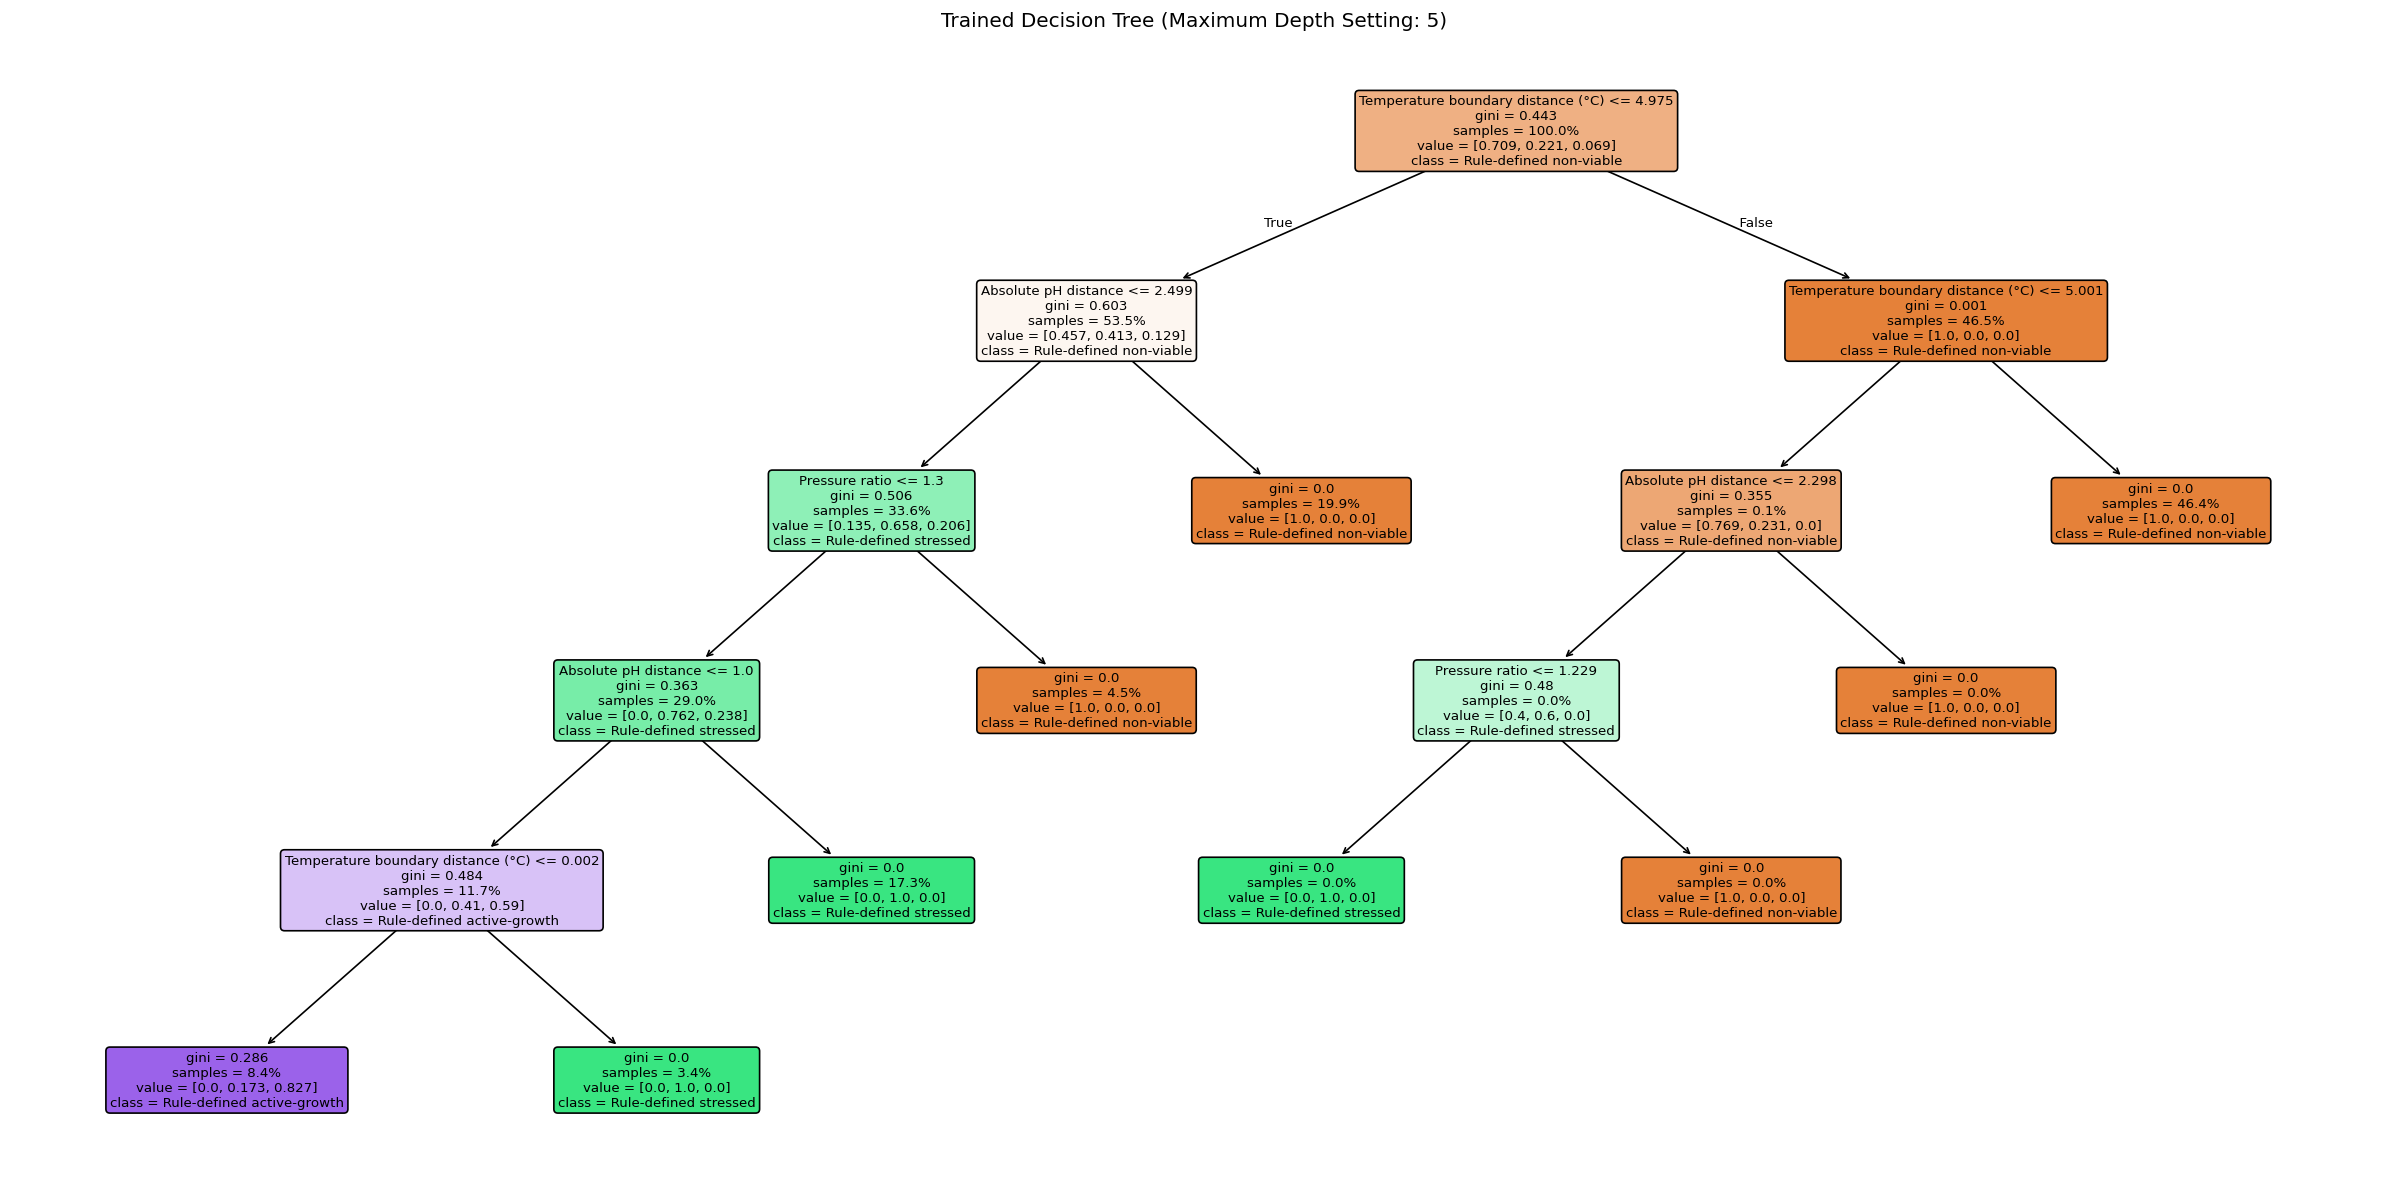

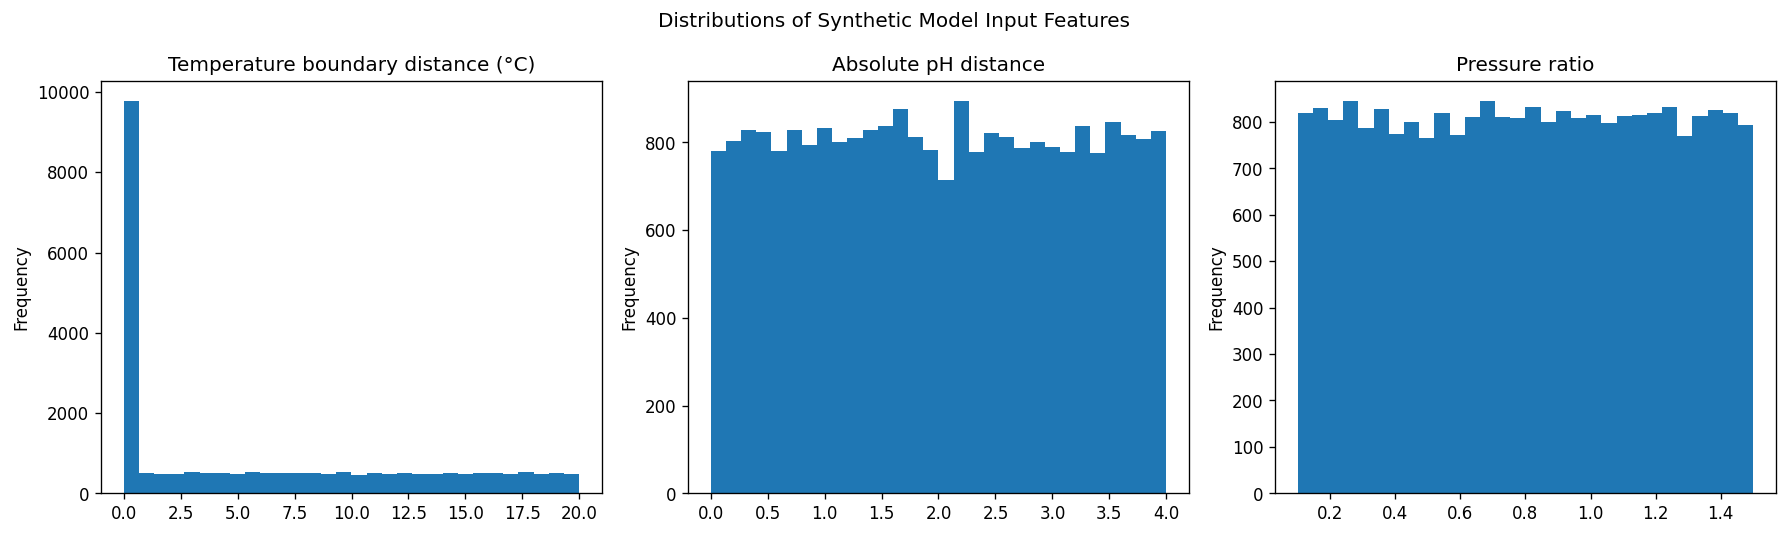

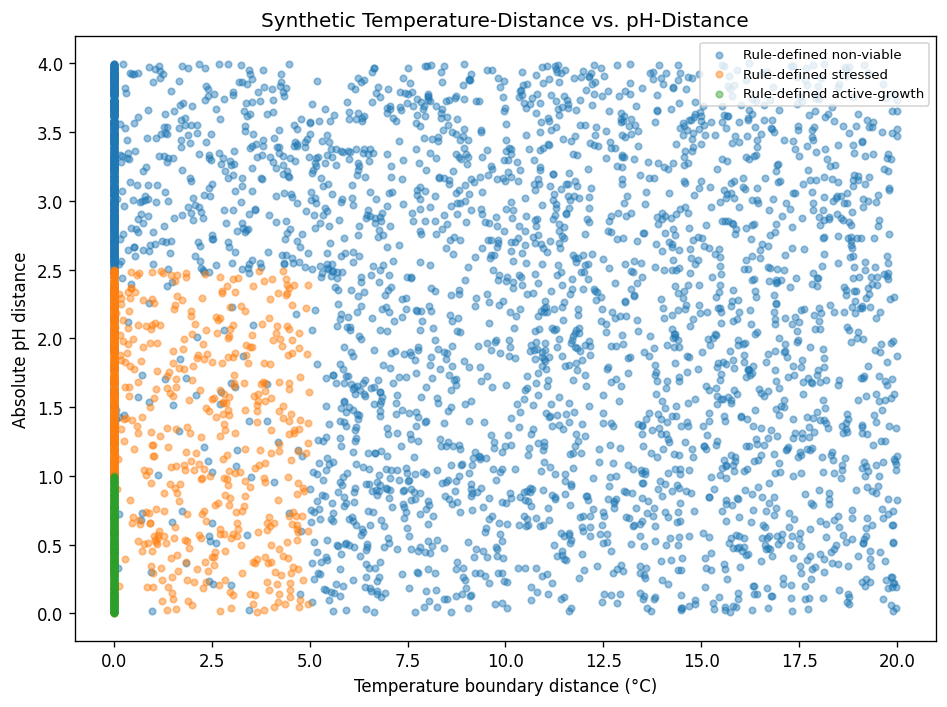

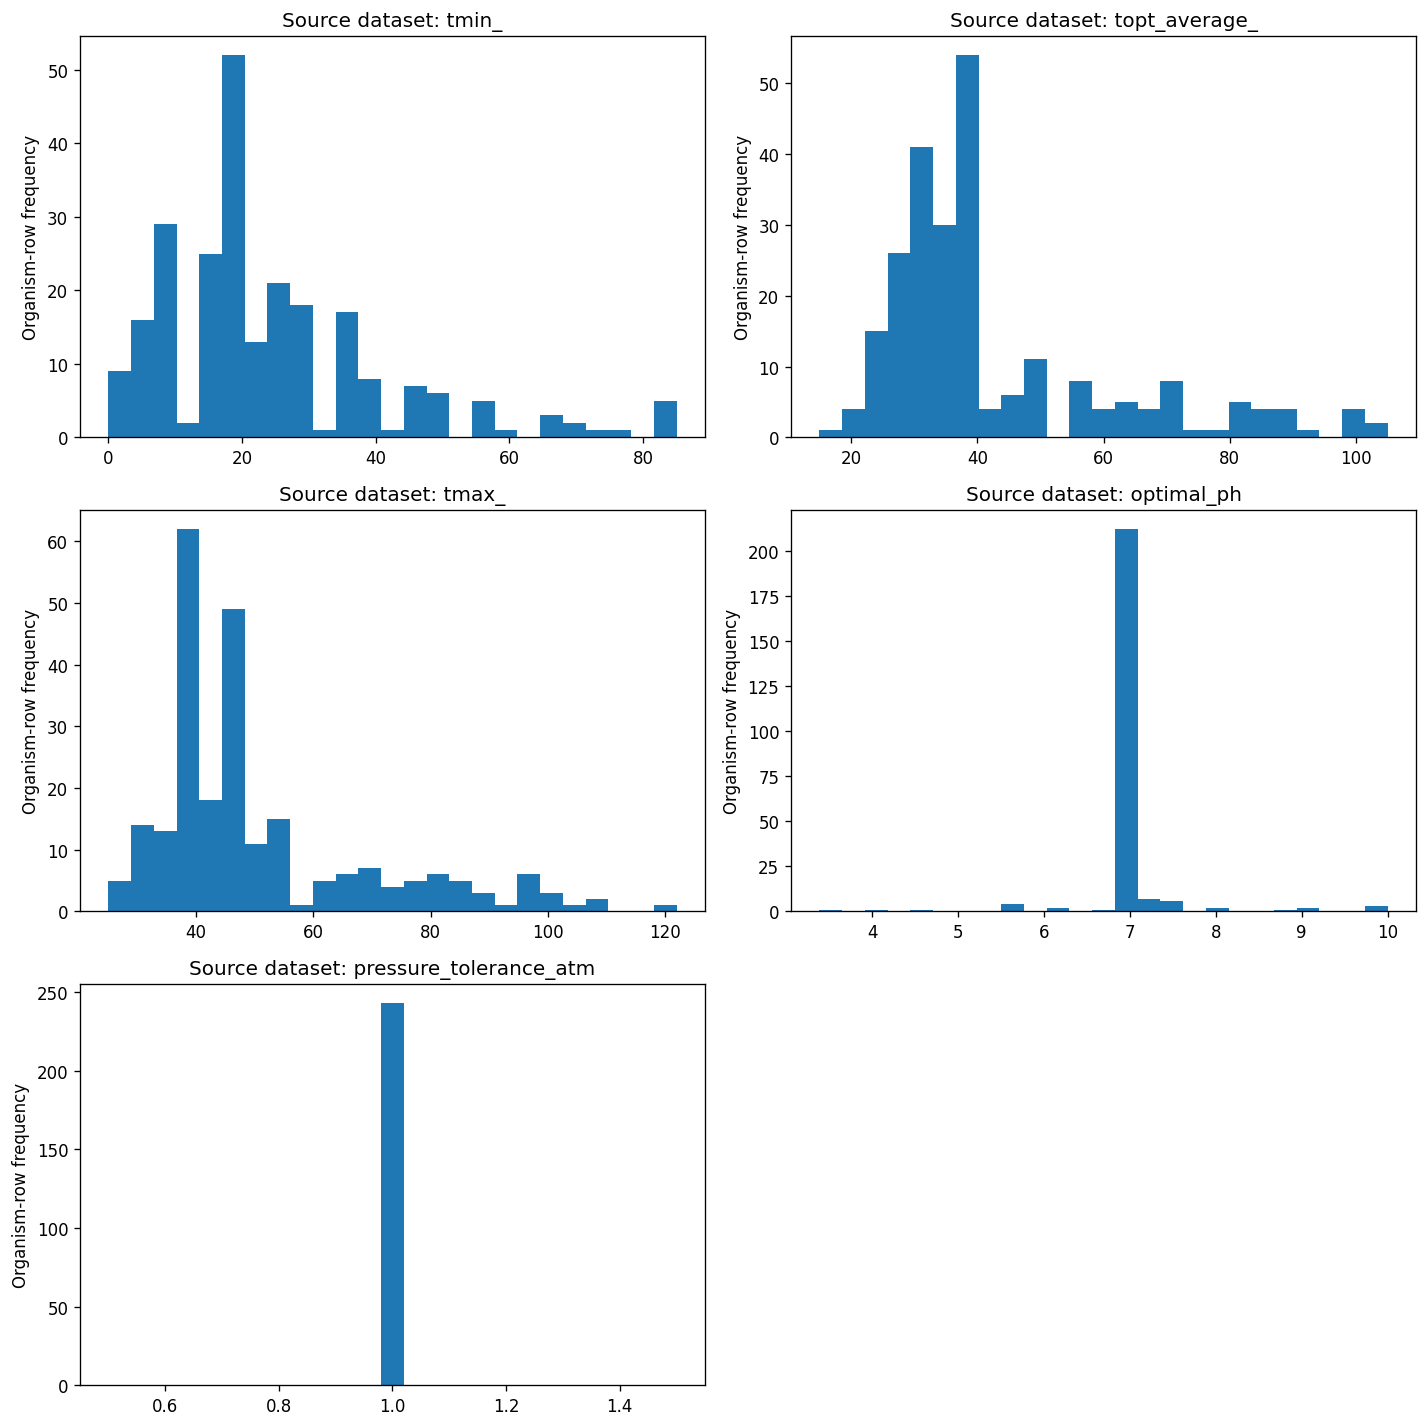


AUTOMATED OUTPUT GENERATION COMPLETE
Output folder: /content/research_outputs
Tables created: 10
Figures created: 7
Open the Files pane in Colab to view or download the research_outputs folder.


In [19]:
# output generation/analysis
# run after the earlier cells have successfully run.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.tree import plot_tree

required_objects = ["df", "X", "y", "X_test", "y_test", "clf"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(
        "Run the earlier data-loading and model-training cells first. "
        f"Missing: {', '.join(missing_objects)}"
    )

# the model's three input features are created in create_training_dataset().
feature_names = [
    "Temperature boundary distance (°C)",
    "Absolute pH distance",
    "Pressure ratio",
]
class_names = {
    0: "Rule-defined non-viable",
    1: "Rule-defined stressed",
    2: "Rule-defined active-growth",
}
class_ids = [0, 1, 2]

output_dir = Path("research_outputs")
tables_dir = output_dir / "tables"
figures_dir = output_dir / "figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# consistent, readable figure defaults. no special color palette is imposed.
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 10})

# source dataset audit
audit_rows = [
    {"metric": "source_dataset_rows", "value": int(len(df))},
    {"metric": "source_dataset_columns", "value": int(df.shape[1])},
    {"metric": "unique_organism_names", "value": int(df["organism_name"].nunique()) if "organism_name" in df.columns else np.nan},
    {"metric": "duplicate_organism_name_rows_after_first", "value": int(df.duplicated("organism_name").sum()) if "organism_name" in df.columns else np.nan},
    {"metric": "total_missing_cells", "value": int(df.isna().sum().sum())},
    {"metric": "synthetic_modeling_observations", "value": int(len(y))},
    {"metric": "number_of_model_features", "value": int(np.asarray(X).shape[1])},
]
source_audit = pd.DataFrame(audit_rows)
source_audit.to_csv(tables_dir / "source_data_audit.csv", index=False)

missing_values = pd.DataFrame({
    "column": df.columns,
    "missing_count": [int(df[col].isna().sum()) for col in df.columns],
    "missing_percent": [float(df[col].isna().mean() * 100) for col in df.columns],
})
missing_values.to_csv(tables_dir / "missing_values_by_column.csv", index=False)

numeric_df = df.select_dtypes(include=[np.number])
if not numeric_df.empty:
    descriptive_stats = numeric_df.describe().T.reset_index().rename(columns={"index": "variable"})
    descriptive_stats.to_csv(tables_dir / "source_numeric_descriptive_statistics.csv", index=False)

# synthetic feature dataset and rule-label counts
X_array = np.asarray(X)
y_array = np.asarray(y).astype(int)
if X_array.ndim != 2 or X_array.shape[1] != len(feature_names):
    raise ValueError(
        f"Expected X to have 3 columns ({feature_names}); got shape {X_array.shape}. "
        "Check that this output cell matches the current training-data function."
    )

modeling_data = pd.DataFrame(X_array, columns=feature_names)
modeling_data["rule_defined_class_id"] = y_array
modeling_data["rule_defined_class"] = [class_names.get(int(v), f"Class {v}") for v in y_array]
modeling_data.to_csv(tables_dir / "synthetic_modeling_dataset.csv", index=False)

class_counts = pd.Series(y_array).value_counts().reindex(class_ids, fill_value=0)
class_distribution = pd.DataFrame({
    "class_id": class_ids,
    "class_name": [class_names[i] for i in class_ids],
    "observation_count": [int(class_counts.loc[i]) for i in class_ids],
    "percentage": [float(class_counts.loc[i] / len(y_array) * 100) if len(y_array) else 0.0 for i in class_ids],
})
class_distribution.to_csv(tables_dir / "synthetic_class_distribution.csv", index=False)

feature_summary = modeling_data[feature_names].describe().T.reset_index().rename(columns={"index": "feature"})
feature_summary.to_csv(tables_dir / "synthetic_feature_descriptive_statistics.csv", index=False)

# holdout model evaluation
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="macro", zero_division=0
)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="weighted", zero_division=0
)

model_metrics = pd.DataFrame([
    {"metric": "holdout_accuracy", "value": float(accuracy)},
    {"metric": "holdout_balanced_accuracy", "value": float(balanced_accuracy)},
    {"metric": "holdout_macro_precision", "value": float(macro_p)},
    {"metric": "holdout_macro_recall", "value": float(macro_r)},
    {"metric": "holdout_macro_f1", "value": float(macro_f1)},
    {"metric": "holdout_weighted_precision", "value": float(weighted_p)},
    {"metric": "holdout_weighted_recall", "value": float(weighted_r)},
    {"metric": "holdout_weighted_f1", "value": float(weighted_f1)},
    {"metric": "training_observations", "value": int(len(y_train))},
    {"metric": "holdout_observations", "value": int(len(y_test))},
    {"metric": "tree_max_depth_setting", "value": int(clf.max_depth) if clf.max_depth is not None else "None"},
    {"metric": "tree_actual_depth", "value": int(clf.get_depth())},
    {"metric": "tree_leaf_count", "value": int(clf.get_n_leaves())},
])
model_metrics.to_csv(tables_dir / "model_performance_metrics.csv", index=False)

report_dict = classification_report(
    y_test,
    y_pred,
    labels=class_ids,
    target_names=[class_names[i] for i in class_ids],
    output_dict=True,
    zero_division=0,
)
classification_report_df = pd.DataFrame(report_dict).T.reset_index().rename(columns={"index": "class_or_average"})
classification_report_df.to_csv(tables_dir / "classification_report.csv", index=False)

cm = confusion_matrix(y_test, y_pred, labels=class_ids)
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {class_names[i]}" for i in class_ids],
    columns=[f"Predicted: {class_names[i]}" for i in class_ids],
)
cm_df.to_csv(tables_dir / "confusion_matrix.csv")

# feature importance
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": clf.feature_importances_,
}).sort_values("importance", ascending=False)
importance_df.to_csv(tables_dir / "decision_tree_feature_importance.csv", index=False)

# figures saved as png files
# figure 1: distribution of generated classes
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(class_distribution["class_name"], class_distribution["observation_count"])
ax.set_title("Distribution of Rule-Defined Synthetic Classes")
ax.set_ylabel("Number of synthetic observations")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(figures_dir / "figure_1_synthetic_class_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# figure 2: confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm, interpolation="nearest")
ax.set_title("Decision Tree Confusion Matrix (Holdout Set)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_xticks(range(len(class_ids)), [class_names[i] for i in class_ids], rotation=20, ha="right")
ax.set_yticks(range(len(class_ids)), [class_names[i] for i in class_ids])
fig.colorbar(image, ax=ax, label="Observation count")
threshold = cm.max() / 2 if cm.size and cm.max() else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black")
fig.tight_layout()
fig.savefig(figures_dir / "figure_2_confusion_matrix.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# figure 3: feature importance
fig, ax = plt.subplots(figsize=(8, 5))
plot_importance = importance_df.sort_values("importance")
ax.barh(plot_importance["feature"], plot_importance["importance"])
ax.set_title("Decision Tree Feature Importance")
ax.set_xlabel("Importance")
fig.tight_layout()
fig.savefig(figures_dir / "figure_3_feature_importance.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# figure 4: trained decision tree
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    clf,
    feature_names=feature_names,
    class_names=[class_names[i] for i in clf.classes_],
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=8,
    ax=ax,
)
ax.set_title("Trained Decision Tree (Maximum Depth Setting: 5)")
fig.tight_layout()
fig.savefig(figures_dir / "figure_4_decision_tree.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# figure 5: generated feature distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, feature in zip(axes, feature_names):
    ax.hist(modeling_data[feature].dropna(), bins=30)
    ax.set_title(feature)
    ax.set_ylabel("Frequency")
fig.suptitle("Distributions of Synthetic Model Input Features")
fig.tight_layout()
fig.savefig(figures_dir / "figure_5_synthetic_feature_distributions.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# figure 6: feature relationship (randomly subsampled only for display if large)
plot_data = modeling_data
if len(plot_data) > 5000:
    plot_data = plot_data.sample(5000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 6))
for class_id in class_ids:
    subset = plot_data[plot_data["rule_defined_class_id"] == class_id]
    ax.scatter(
        subset[feature_names[0]],
        subset[feature_names[1]],
        label=class_names[class_id],
        alpha=0.45,
        s=15,
    )
ax.set_title("Synthetic Temperature-Distance vs. pH-Distance")
ax.set_xlabel(feature_names[0])
ax.set_ylabel(feature_names[1])
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures_dir / "figure_6_temperature_ph_relationship.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# figure 7: source environmental-variable distributions, where available
source_plot_columns = [c for c in ["tmin_", "topt_average_", "tmax_", "optimal_ph", "pressure_tolerance_atm"] if c in df.columns]
if source_plot_columns:
    ncols = 2
    nrows = int(np.ceil(len(source_plot_columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, source_plot_columns):
        vals = pd.to_numeric(df[col], errors="coerce").dropna()
        ax.hist(vals, bins=25)
        ax.set_title(f"Source dataset: {col}")
        ax.set_ylabel("Organism-row frequency")
    for ax in axes[len(source_plot_columns):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(figures_dir / "figure_7_source_variable_distributions.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

# reproducability and interpretation notes
notes = {
    "project_title": "Evaluating a Decision-Tree Classifier for Rule-Defined Environmental Categories in a Synthetic Microbial Dataset",
    "model": "DecisionTreeClassifier",
    "maximum_depth_setting": clf.max_depth,
    "features": feature_names,
    "class_definitions": class_names,
    "synthetic_observations": int(len(y_array)),
    "train_test_split": "80/20 random split with random_state=42 in the existing notebook",
    "synthetic_generation_seed": 42,
    "interpretation_limitations": [
        "The target categories are generated by explicit rules in the notebook; they are not experimentally measured microbial survival outcomes.",
        "The holdout split is performed across synthetic observations, not grouped by organism. Observations from the same source organisms may appear in both training and holdout sets, so holdout metrics should not be described as organism-independent generalization.",
        "Missing optimal pH values are filled with 7.0 in the data-preparation cell; this is an imputation assumption and not a measured optimum.",
        "Pressure tolerance is assigned using organism-name keyword heuristics in the data-preparation cell; it is not a direct measurement from the two source datasets.",
        "The estimated survival durations printed by the interactive predictor are heuristic text labels and are not validated by this classifier or by experimental time-to-survival data."
    ],
}
with open(output_dir / "analysis_metadata_and_limitations.json", "w", encoding="utf-8") as f:
    json.dump(notes, f, indent=2)

with open(output_dir / "README.txt", "w", encoding="utf-8") as f:
    f.write("AUTOMATED RESEARCH OUTPUTS\n")
    f.write("=========================\n\n")
    f.write("tables/: CSV files containing dataset audits, descriptive statistics, class counts, and model results.\n")
    f.write("figures/: High-resolution PNG figures generated from the current notebook run.\n\n")
    f.write("IMPORTANT INTERPRETATION NOTES\n")
    for item in notes["interpretation_limitations"]:
        f.write(f"- {item}\n")

print("\nAUTOMATED OUTPUT GENERATION COMPLETE")
print(f"Output folder: {output_dir.resolve()}")
print(f"Tables created: {len(list(tables_dir.glob('*.csv')))}")
print(f"Figures created: {len(list(figures_dir.glob('*.png')))}")
print("Open the Files pane in Colab to view or download the research_outputs folder.")


In [20]:
# two feauture method

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report
)

# reproducibility and analysis settings
REVISED_SEED = 42
REVISED_SAMPLES_PER_ROW = 100
REVISED_TEST_SIZE = 0.20
REVISED_N_SPLITS = 10
REVISED_TREE_DEPTHS = [1, 2, 3, 4, 5, 6, 7, 8, None]
REVISED_FEATURES = [
    "temperature_boundary_distance_C",
    "pH_distance_from_optimum",
]
REVISED_CLASS_NAMES = {
    0: "outside programmed limits",
    1: "within broader/stress limits",
    2: "within strict/optimal limits",
}

# check that the original data-preparation cell has run.
if "df" not in globals():
    raise NameError("The original data-preparation/model cell must run first; it creates `df`.")

required_columns = ["organism_name", "tmin_", "tmax_", "optimal_ph"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Your source dataframe is missing required columns: {missing_columns}")

# make a clean COPY. do not alter the original df.
revised_source = df.copy()
for col in ["tmin_", "tmax_", "optimal_ph"]:
    revised_source[col] = pd.to_numeric(revised_source[col], errors="coerce")

revised_source["taxonomy_id"] = (
    revised_source["organism_name"].astype("string").str.strip()
)
revised_source = revised_source.replace(
    {"taxonomy_id": {"": pd.NA, "nan": pd.NA, "None": pd.NA}}
)
revised_source = revised_source.dropna(
    subset=["taxonomy_id", "tmin_", "tmax_", "optimal_ph"]
).copy()
revised_source = revised_source[
    revised_source["tmax_"] >= revised_source["tmin_"]
].copy()
revised_source.reset_index(drop=True, inplace=True)

if revised_source.empty:
    raise ValueError("No usable source rows remain after checking organism names and temperature/pH values.")
if revised_source["taxonomy_id"].nunique() < 2:
    raise ValueError("Grouped train/test evaluation requires at least two unique organism identifiers.")

# explicit programmed class rules. Class 2 has priority over Class 1.
def revised_assign_label(temp_distance, ph_distance):
    if temp_distance == 0 and ph_distance <= 1.0:
        return 2
    if temp_distance <= 5.0 and ph_distance <= 2.5:
        return 1
    return 0

# generate 100 synthetic environmental observations per usable source row.
revised_rng = np.random.default_rng(REVISED_SEED)
revised_records = []

for source_index, row in revised_source.iterrows():
    tmin = float(row["tmin_"])
    tmax = float(row["tmax_"])
    ph_opt = float(row["optimal_ph"])

    for sample_number in range(REVISED_SAMPLES_PER_ROW):
        simulated_temp = revised_rng.uniform(tmin - 20.0, tmax + 20.0)
        ph_low = max(0.0, ph_opt - 4.0)
        ph_high = min(14.0, ph_opt + 4.0)
        simulated_ph = revised_rng.uniform(ph_low, ph_high)

        if simulated_temp < tmin:
            temp_distance = tmin - simulated_temp
        elif simulated_temp > tmax:
            temp_distance = simulated_temp - tmax
        else:
            temp_distance = 0.0

        ph_distance = abs(simulated_ph - ph_opt)
        rule_label = revised_assign_label(temp_distance, ph_distance)

        revised_records.append({
            "source_row_index": int(source_index),
            "taxonomy_id": str(row["taxonomy_id"]),
            "simulated_temperature_C": simulated_temp,
            "simulated_pH": simulated_ph,
            REVISED_FEATURES[0]: temp_distance,
            REVISED_FEATURES[1]: ph_distance,
            "rule_label": rule_label,
        })

revised_samples = pd.DataFrame(revised_records)

# a single grouped holdout is used for depth comparison and the detailed report.
revised_splitter = GroupShuffleSplit(
    n_splits=1, test_size=REVISED_TEST_SIZE, random_state=REVISED_SEED
)
revised_train_idx, revised_test_idx = next(
    revised_splitter.split(
        revised_samples[REVISED_FEATURES],
        revised_samples["rule_label"],
        groups=revised_samples["taxonomy_id"],
    )
)
revised_train = revised_samples.iloc[revised_train_idx].copy()
revised_test = revised_samples.iloc[revised_test_idx].copy()

# safety check: no source organism may appear in both partitions.
revised_overlap = set(revised_train["taxonomy_id"]) & set(revised_test["taxonomy_id"])
if revised_overlap:
    raise RuntimeError(f"Taxonomy/organism leakage detected: {len(revised_overlap)} IDs overlap.")

# compare tree depths using exactly the same grouped holdout.
revised_depth_rows = []
revised_models_by_depth = {}
for depth in REVISED_TREE_DEPTHS:
    model = DecisionTreeClassifier(max_depth=depth, random_state=REVISED_SEED)
    model.fit(revised_train[REVISED_FEATURES], revised_train["rule_label"])
    predictions = model.predict(revised_test[REVISED_FEATURES])
    revised_models_by_depth[depth] = model
    revised_depth_rows.append({
        "max_depth": "unlimited" if depth is None else depth,
        "holdout_accuracy": accuracy_score(revised_test["rule_label"], predictions),
        "holdout_macro_f1": f1_score(
            revised_test["rule_label"], predictions, average="macro", zero_division=0
        ),
    })

revised_depth_table = pd.DataFrame(revised_depth_rows)
revised_model = revised_models_by_depth[5]
revised_predictions = revised_model.predict(revised_test[REVISED_FEATURES])
revised_confusion = confusion_matrix(
    revised_test["rule_label"], revised_predictions, labels=[0, 1, 2]
)

print("REVISED TWO-FEATURE ANALYSIS")
print(f"Usable source rows: {len(revised_source):,}")
print(f"Unique organism/taxonomy identifiers: {revised_source['taxonomy_id'].nunique():,}")
print(f"Synthetic observations: {len(revised_samples):,}")
print(f"Training organisms: {revised_train['taxonomy_id'].nunique():,}")
print(f"Test organisms: {revised_test['taxonomy_id'].nunique():,}")
print("Features:", REVISED_FEATURES)
print("\nDepth comparison:")
display(revised_depth_table)
print("\nDepth-5 classification report:")
print(classification_report(
    revised_test["rule_label"], revised_predictions,
    labels=[0, 1, 2],
    target_names=[REVISED_CLASS_NAMES[i] for i in [0, 1, 2]],
    zero_division=0,
))
print("\nIMPORTANT: these metrics measure agreement with programmed synthetic labels, not biological survival.")


REVISED TWO-FEATURE ANALYSIS
Usable source rows: 243
Unique organism/taxonomy identifiers: 242
Synthetic observations: 24,300
Training organisms: 193
Test organisms: 49
Features: ['temperature_boundary_distance_C', 'pH_distance_from_optimum']

Depth comparison:


,max_depth,holdout_accuracy,holdout_macro_f1
0,1,0.695306,0.477656
1,2,0.895102,0.607248
2,3,0.960612,0.917906
3,4,0.999796,0.999807
4,5,0.999796,0.999807
5,6,0.999796,0.999807
6,7,0.999796,0.999807
7,8,0.999796,0.999807
8,unlimited,0.999796,0.999807



Depth-5 classification report:
                              precision    recall  f1-score   support

   outside programmed limits       1.00      1.00      1.00      3201
within broader/stress limits       1.00      1.00      1.00      1186
within strict/optimal limits       1.00      1.00      1.00       513

                    accuracy                           1.00      4900
                   macro avg       1.00      1.00      1.00      4900
                weighted avg       1.00      1.00      1.00      4900


IMPORTANT: these metrics measure agreement with programmed synthetic labels, not biological survival.


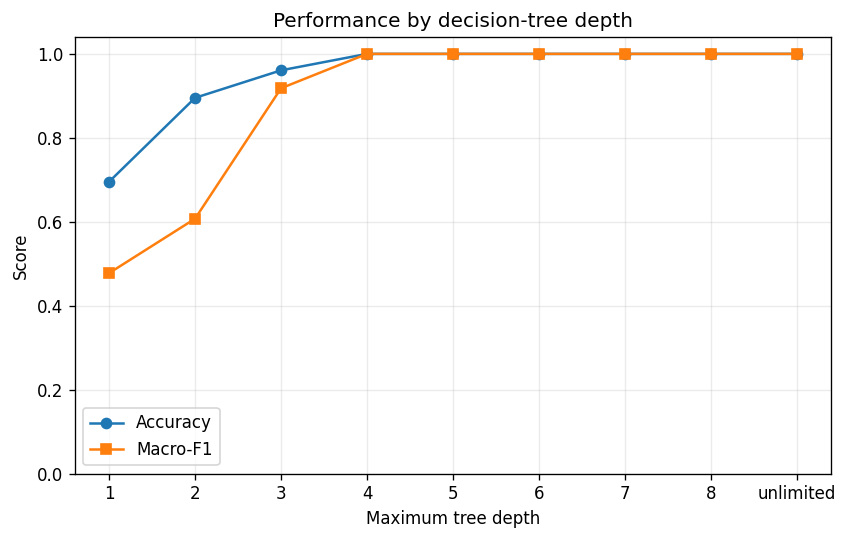

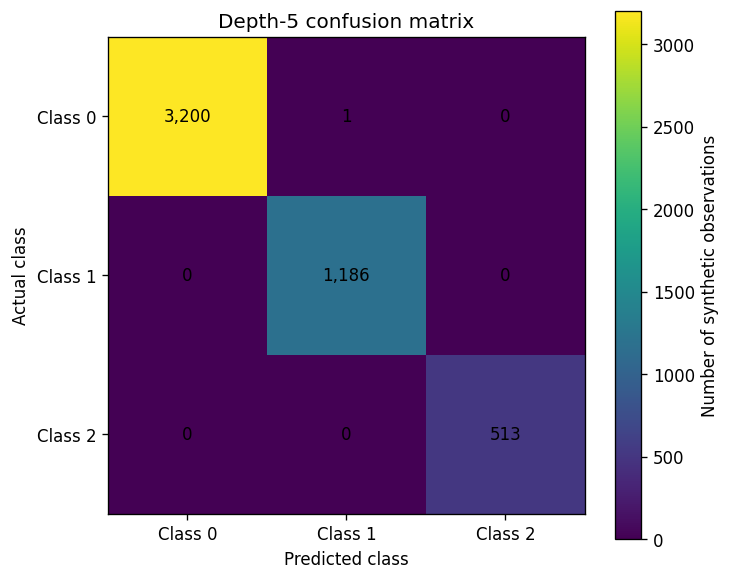

/tmp/ipykernel_2138/221503553.py:178: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(revised_group_results["accuracy"], labels=["Depth 5"])


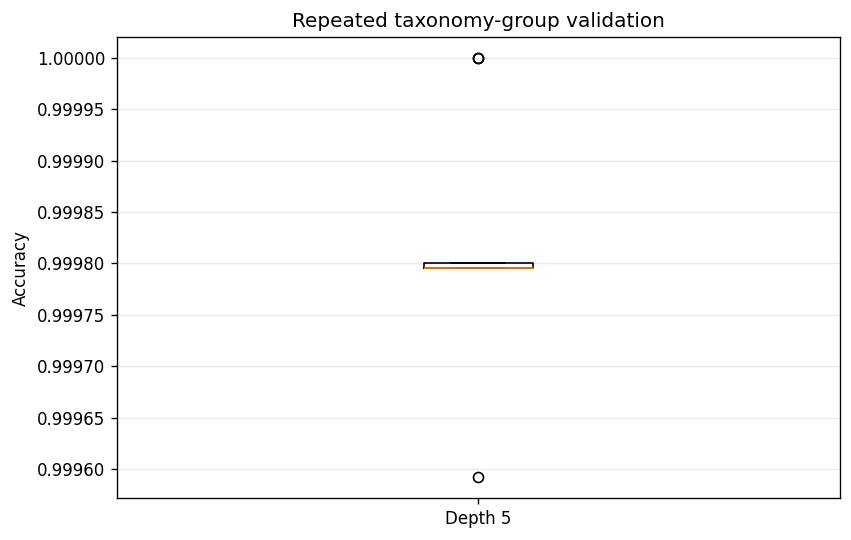

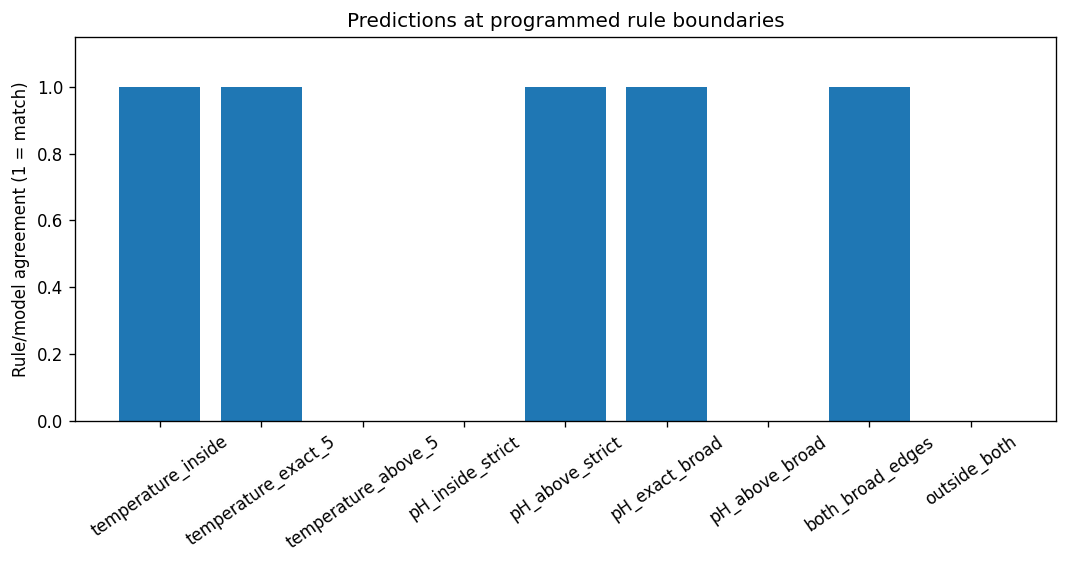

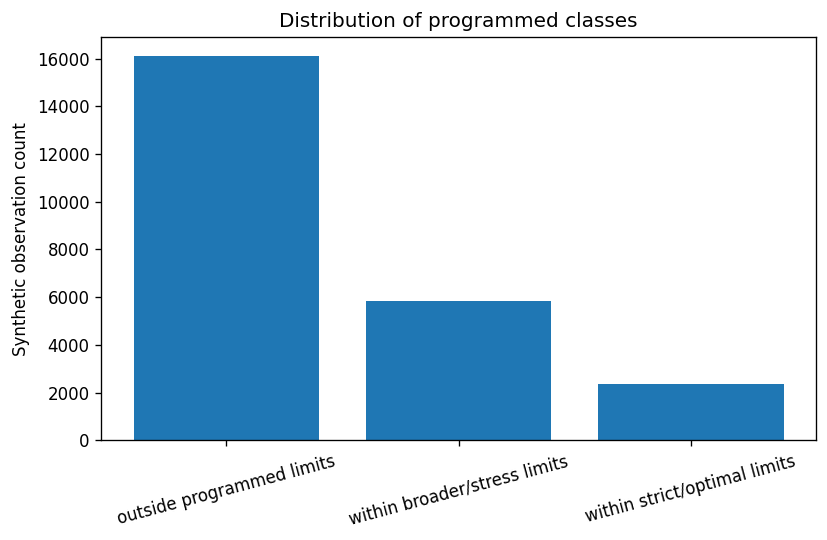


SIX MANUSCRIPT TABLES CREATED:
 - revised_results/tables/table1_rule_definitions.csv
 - revised_results/tables/table2_dataset_summary.csv
 - revised_results/tables/table3_tree_depth_comparison.csv
 - revised_results/tables/table4_confusion_matrix.csv
 - revised_results/tables/table5_grouped_validation_summary.csv
 - revised_results/tables/table6_boundary_probes.csv

FIVE MANUSCRIPT FIGURES CREATED:
 - revised_results/figures/figure1_tree_depth.png
 - revised_results/figures/figure2_confusion_matrix.png
 - revised_results/figures/figure3_grouped_validation.png
 - revised_results/figures/figure4_boundary_tests.png
 - revised_results/figures/figure5_class_distribution.png

Actual run summary:


,value
source_rows_used,243
unique_organism_taxonomy_identifiers,242
synthetic_observations,24300
class_counts,"{'0': 16097, '1': 5852, '2': 2351}"
features,"[temperature_boundary_distance_C, pH_distance_..."
pressure_excluded,True
grouped_holdout_training_organisms,193
grouped_holdout_test_organisms,49
depth5_holdout_accuracy,0.999796
depth5_holdout_macro_f1,0.999807



ZIP archive created: /content/revised_results.zip
All revised outputs saved in: /content/revised_results
Reminder: synthetic-label agreement is not evidence of real microbial survival prediction.


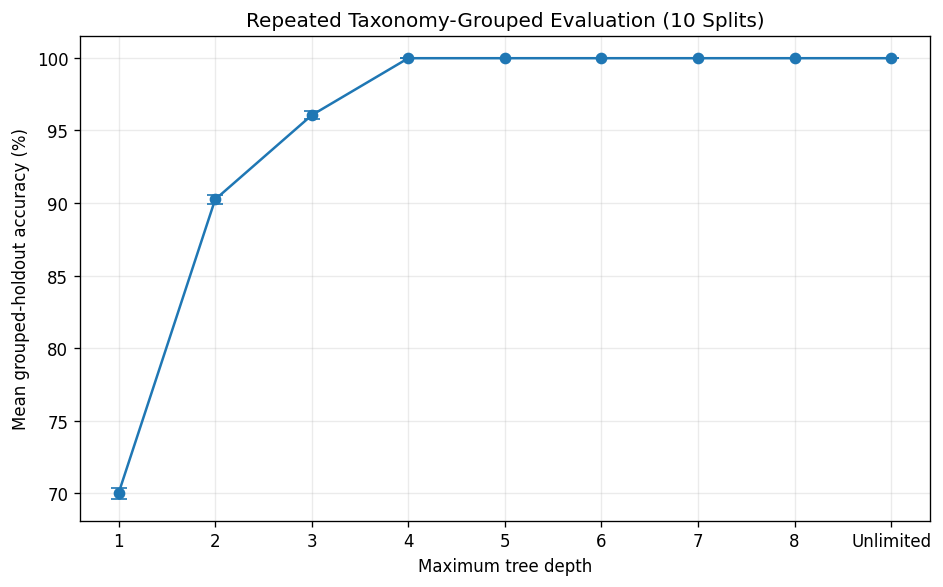

In [21]:
# manuscript graphs, tables, and charts

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score

REVISED_OUT = Path("revised_results")
REVISED_FIGURES = REVISED_OUT / "figures"
REVISED_TABLES = REVISED_OUT / "tables"
REVISED_FIGURES.mkdir(parents=True, exist_ok=True)
REVISED_TABLES.mkdir(parents=True, exist_ok=True)

# manuscript table 1: operational rule definitions
table1 = pd.DataFrame([
    {"class": 2, "operational_rule": "Temperature-boundary distance = 0 and pH distance <= 1.0", "interpretation": REVISED_CLASS_NAMES[2]},
    {"class": 1, "operational_rule": "Not Class 2; temperature-boundary distance <= 5.0 and pH distance <= 2.5", "interpretation": REVISED_CLASS_NAMES[1]},
    {"class": 0, "operational_rule": "All remaining combinations", "interpretation": REVISED_CLASS_NAMES[0]},
])
table1.to_csv(REVISED_TABLES / "table1_rule_definitions.csv", index=False)

# manuscript table 2: source and synthetic dataset summary
class_counts = revised_samples["rule_label"].value_counts().reindex([0, 1, 2], fill_value=0)
table2 = pd.DataFrame([
    {"measure": "usable_source_rows", "value": len(revised_source)},
    {"measure": "unique_organism_taxonomy_identifiers", "value": revised_source["taxonomy_id"].nunique()},
    {"measure": "synthetic_observations", "value": len(revised_samples)},
    {"measure": "observations_per_source_row", "value": REVISED_SAMPLES_PER_ROW},
    {"measure": "class_0_count", "value": int(class_counts.loc[0])},
    {"measure": "class_0_percent", "value": float(class_counts.loc[0] / len(revised_samples) * 100)},
    {"measure": "class_1_count", "value": int(class_counts.loc[1])},
    {"measure": "class_1_percent", "value": float(class_counts.loc[1] / len(revised_samples) * 100)},
    {"measure": "class_2_count", "value": int(class_counts.loc[2])},
    {"measure": "class_2_percent", "value": float(class_counts.loc[2] / len(revised_samples) * 100)},
    {"measure": "number_of_model_features", "value": len(REVISED_FEATURES)},
])
table2.to_csv(REVISED_TABLES / "table2_dataset_summary.csv", index=False)

# save the class distribution as a separate supplementary table too.
class_distribution = pd.DataFrame({
    "class": [0, 1, 2],
    "class_name": [REVISED_CLASS_NAMES[i] for i in [0, 1, 2]],
    "observation_count": [int(class_counts.loc[i]) for i in [0, 1, 2]],
    "percentage": [float(class_counts.loc[i] / len(revised_samples) * 100) for i in [0, 1, 2]],
})
class_distribution.to_csv(REVISED_TABLES / "class_distribution.csv", index=False)

# manuscript Table 3: depth comparison
table3 = revised_depth_table.copy()
table3.to_csv(REVISED_TABLES / "table3_tree_depth_comparison.csv", index=False)

#  manuscript table 4: confusion matrix
table4 = pd.DataFrame(
    revised_confusion,
    index=[f"Actual class {i}" for i in [0, 1, 2]],
    columns=[f"Predicted class {i}" for i in [0, 1, 2]],
)
table4.to_csv(REVISED_TABLES / "table4_confusion_matrix.csv")

#  manuscript table 5: repeated grouped validation
revised_group_splitter = GroupShuffleSplit(
    n_splits=REVISED_N_SPLITS,
    test_size=REVISED_TEST_SIZE,
    random_state=REVISED_SEED,
)
revised_group_rows = []
for split_number, (train_idx, test_idx) in enumerate(
    revised_group_splitter.split(
        revised_samples[REVISED_FEATURES],
        revised_samples["rule_label"],
        groups=revised_samples["taxonomy_id"],
    ), start=1
):
    split_train = revised_samples.iloc[train_idx]
    split_test = revised_samples.iloc[test_idx]
    overlap = set(split_train["taxonomy_id"]) & set(split_test["taxonomy_id"])
    if overlap:
        raise RuntimeError("Grouped validation failed: an organism occurs in both partitions.")

    split_model = DecisionTreeClassifier(max_depth=5, random_state=REVISED_SEED)
    split_model.fit(split_train[REVISED_FEATURES], split_train["rule_label"])
    split_pred = split_model.predict(split_test[REVISED_FEATURES])
    revised_group_rows.append({
        "split": split_number,
        "accuracy": accuracy_score(split_test["rule_label"], split_pred),
        "macro_f1": f1_score(split_test["rule_label"], split_pred, average="macro", zero_division=0),
        "training_organisms": split_train["taxonomy_id"].nunique(),
        "test_organisms": split_test["taxonomy_id"].nunique(),
    })

revised_group_results = pd.DataFrame(revised_group_rows)
revised_group_summary = pd.DataFrame([
    {"metric": "accuracy_mean", "value": revised_group_results["accuracy"].mean()},
    {"metric": "accuracy_sd", "value": revised_group_results["accuracy"].std(ddof=1)},
    {"metric": "macro_f1_mean", "value": revised_group_results["macro_f1"].mean()},
    {"metric": "macro_f1_sd", "value": revised_group_results["macro_f1"].std(ddof=1)},
])
revised_group_results.to_csv(REVISED_TABLES / "grouped_validation_by_split.csv", index=False)
revised_group_summary.to_csv(REVISED_TABLES / "table5_grouped_validation_summary.csv", index=False)

# manuscript table 6: nine boundary probes
eps = 1e-6
revised_boundary_cases = [
    ("temperature_inside", 0.0, 0.5),
    ("temperature_exact_5", 5.0, 2.0),
    ("temperature_above_5", 5.0 + eps, 2.0),
    ("pH_inside_strict", 0.0, 1.0),
    ("pH_above_strict", 0.0, 1.0 + eps),
    ("pH_exact_broad", 2.0, 2.5),
    ("pH_above_broad", 2.0, 2.5 + eps),
    ("both_broad_edges", 5.0, 2.5),
    ("outside_both", 5.0 + eps, 2.5 + eps),
]
revised_boundary_rows = []
for scenario, temp_distance, ph_distance in revised_boundary_cases:
    expected = revised_assign_label(temp_distance, ph_distance)
    probe = pd.DataFrame([{
        REVISED_FEATURES[0]: temp_distance,
        REVISED_FEATURES[1]: ph_distance,
    }])
    predicted = int(revised_model.predict(probe)[0])
    revised_boundary_rows.append({
        "scenario": scenario,
        "temperature_boundary_distance_C": temp_distance,
        "pH_distance_from_optimum": ph_distance,
        "expected_class": expected,
        "predicted_class": predicted,
        "agreement": expected == predicted,
    })
revised_boundary = pd.DataFrame(revised_boundary_rows)
revised_boundary.to_csv(REVISED_TABLES / "table6_boundary_probes.csv", index=False)

revised_samples.to_csv(REVISED_OUT / "revised_simulated_samples.csv", index=False)
revised_source[["taxonomy_id", "tmin_", "tmax_", "optimal_ph"]].describe().T.to_csv(
    REVISED_TABLES / "source_variable_descriptives.csv"
)
revised_samples[REVISED_FEATURES + ["rule_label"]].describe().T.to_csv(
    REVISED_TABLES / "synthetic_feature_descriptives.csv"
)
revised_source_audit = pd.DataFrame([
    {"metric": "usable_source_rows", "value": len(revised_source)},
    {"metric": "unique_organism_taxonomy_identifiers", "value": revised_source["taxonomy_id"].nunique()},
    {"metric": "rows_with_optimal_pH_exactly_7", "value": int((revised_source["optimal_ph"] == 7.0).sum())},
    {"metric": "rows_with_repeated_identifier", "value": int(revised_source.duplicated("taxonomy_id", keep=False).sum())},
    {"metric": "pressure_excluded", "value": True},
])
revised_source_audit.to_csv(REVISED_TABLES / "source_data_audit.csv", index=False)
(REVISED_OUT / "depth5_tree_rules.txt").write_text(
    export_text(revised_model, feature_names=REVISED_FEATURES)
)


# figure 1: tree-depth comparison
fig, ax = plt.subplots(figsize=(7.2, 4.6))
labels = revised_depth_table["max_depth"].astype(str)
ax.plot(labels, revised_depth_table["holdout_accuracy"], marker="o", label="Accuracy")
ax.plot(labels, revised_depth_table["holdout_macro_f1"], marker="s", label="Macro-F1")
ax.set(xlabel="Maximum tree depth", ylabel="Score", ylim=(0, 1.04), title="Performance by decision-tree depth")
ax.grid(True, alpha=0.25); ax.legend(); fig.tight_layout()
fig.savefig(REVISED_FIGURES / "figure1_tree_depth.png", dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)

# figure 2: confusion matrix
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(revised_confusion, interpolation="nearest")
ax.set(xticks=range(3), yticks=range(3), xticklabels=["Class 0", "Class 1", "Class 2"],
       yticklabels=["Class 0", "Class 1", "Class 2"], xlabel="Predicted class", ylabel="Actual class",
       title="Depth-5 confusion matrix")
for i in range(3):
    for j in range(3): ax.text(j, i, f"{revised_confusion[i, j]:,}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Number of synthetic observations"); fig.tight_layout()
fig.savefig(REVISED_FIGURES / "figure2_confusion_matrix.png", dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)

# figure 3: repeated grouped-validation accuracy
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.boxplot(revised_group_results["accuracy"], labels=["Depth 5"])
ax.set(ylabel="Accuracy", title="Repeated taxonomy-group validation")
ax.grid(True, axis="y", alpha=0.25); fig.tight_layout()
fig.savefig(REVISED_FIGURES / "figure3_grouped_validation.png", dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)

# figure 4: boundary probe agreement
fig, ax = plt.subplots(figsize=(9.0, 4.8))
ax.bar(revised_boundary["scenario"], revised_boundary["agreement"].astype(int))
ax.set(ylim=(0, 1.15), ylabel="Rule/model agreement (1 = match)", title="Predictions at programmed rule boundaries")
ax.tick_params(axis="x", rotation=35); fig.tight_layout()
fig.savefig(REVISED_FIGURES / "figure4_boundary_tests.png", dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)

# figure 5: synthetic class distribution
fig, ax = plt.subplots(figsize=(7.0, 4.6))
ax.bar([REVISED_CLASS_NAMES[i] for i in [0, 1, 2]], [int(class_counts.loc[i]) for i in [0, 1, 2]])
ax.set(ylabel="Synthetic observation count", title="Distribution of programmed classes")
ax.tick_params(axis="x", rotation=15); fig.tight_layout()
fig.savefig(REVISED_FIGURES / "figure5_class_distribution.png", dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)

# run summary: use actual results from this execution, not previously reported values.
revised_summary = {
    "source_rows_used": int(len(revised_source)),
    "unique_organism_taxonomy_identifiers": int(revised_source["taxonomy_id"].nunique()),
    "synthetic_observations": int(len(revised_samples)),
    "class_counts": {str(i): int(class_counts.loc[i]) for i in [0, 1, 2]},
    "features": REVISED_FEATURES,
    "pressure_excluded": True,
    "grouped_holdout_training_organisms": int(revised_train["taxonomy_id"].nunique()),
    "grouped_holdout_test_organisms": int(revised_test["taxonomy_id"].nunique()),
    "depth5_holdout_accuracy": float(accuracy_score(revised_test["rule_label"], revised_predictions)),
    "depth5_holdout_macro_f1": float(f1_score(revised_test["rule_label"], revised_predictions, average="macro", zero_division=0)),
    "boundary_probe_matches": int(revised_boundary["agreement"].sum()),
    "boundary_probe_total": int(len(revised_boundary)),
    "grouped_validation_accuracy_mean": float(revised_group_results["accuracy"].mean()),
    "grouped_validation_accuracy_sd": float(revised_group_results["accuracy"].std(ddof=1)),
    "interpretation_limit": "Metrics measure reproduction of programmed synthetic labels, not experimentally measured microbial viability or survival.",
    "pH_provenance_warning": "The original preparation cell fills missing optimal pH values with 7.0; the processed dataframe does not preserve which values were originally missing.",
}
(REVISED_OUT / "run_summary.json").write_text(json.dumps(revised_summary, indent=2))

print("\nSIX MANUSCRIPT TABLES CREATED:")
for filename in [
    "table1_rule_definitions.csv", "table2_dataset_summary.csv",
    "table3_tree_depth_comparison.csv", "table4_confusion_matrix.csv",
    "table5_grouped_validation_summary.csv", "table6_boundary_probes.csv",
]:
    print(" -", REVISED_TABLES / filename)
print("\nFIVE MANUSCRIPT FIGURES CREATED:")
for path in sorted(REVISED_FIGURES.glob("*.png")):
    print(" -", path)
print("\nActual run summary:")
display(pd.DataFrame([revised_summary]).T.rename(columns={0: "value"}))
import shutil
revised_zip_path = shutil.make_archive("revised_results", "zip", root_dir=REVISED_OUT)
print("\nZIP archive created:", revised_zip_path)
print("All revised outputs saved in:", REVISED_OUT.resolve())
print("Reminder: synthetic-label agreement is not evidence of real microbial survival prediction.")


# graph: repeated grouped-validation accuracy across all tree depths

depths = REVISED_TREE_DEPTHS
splitter = GroupShuffleSplit(n_splits=10, test_size=0.20, random_state=42)
results = []

for train_idx, test_idx in splitter.split(
    revised_samples[REVISED_FEATURES],
    revised_samples["rule_label"],
    groups=revised_samples["taxonomy_id"]
):
    train = revised_samples.iloc[train_idx]
    test = revised_samples.iloc[test_idx]

    for depth in depths:
        model = DecisionTreeClassifier(max_depth=depth, random_state=42)
        model.fit(train[REVISED_FEATURES], train["rule_label"])
        pred = model.predict(test[REVISED_FEATURES])

        results.append({
            "depth": "Unlimited" if depth is None else str(depth),
            "accuracy": accuracy_score(test["rule_label"], pred)
        })

results_df = pd.DataFrame(results)
summary = results_df.groupby("depth", sort=False)["accuracy"].agg(["mean", "std"])

plt.figure(figsize=(8, 5))
plt.errorbar(
    summary.index,
    summary["mean"] * 100,
    yerr=summary["std"] * 100,
    marker="o",
    capsize=5
)

plt.xlabel("Maximum tree depth")
plt.ylabel("Mean grouped-holdout accuracy (%)")
plt.title("Repeated Taxonomy-Grouped Evaluation (10 Splits)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(REVISED_FIGURES / "figure3_all_tree_depths.png", dpi=300)
plt.show()



In [22]:
# mathematical calculations

from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    confusion_matrix,
    classification_report,
)

required_objects = [
    "revised_source", "revised_samples", "revised_train", "revised_test",
    "REVISED_FEATURES", "REVISED_TREE_DEPTHS", "REVISED_TEST_SIZE",
    "REVISED_SEED", "REVISED_N_SPLITS", "REVISED_SAMPLES_PER_ROW",
    "revised_assign_label", "revised_model", "revised_predictions",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(
        "Run the revised two-feature analysis cell and the manuscript-output cell first. "
        f"Missing objects: {', '.join(missing_objects)}"
    )

CALC_DIR = Path("revised_results") / "mathematical_calculations"
CALC_DIR.mkdir(parents=True, exist_ok=True)
FEATURES = list(REVISED_FEATURES)
CLASS_ORDER = [0, 1, 2]

# recalculate feature engineering from raw simulated values
source_for_recalculation = revised_source.reset_index(drop=True).copy()
source_for_recalculation["source_row_index"] = source_for_recalculation.index
recheck = revised_samples.merge(
    source_for_recalculation[["source_row_index", "tmin_", "tmax_", "optimal_ph"]],
    on="source_row_index",
    how="left",
    validate="many_to_one",
)

if recheck[["tmin_", "tmax_", "optimal_ph"]].isna().any().any():
    raise ValueError("Some simulated observations could not be matched to their source rows.")

T = recheck["simulated_temperature_C"].astype(float)
TMIN = recheck["tmin_"].astype(float)
TMAX = recheck["tmax_"].astype(float)
PH_SIM = recheck["simulated_pH"].astype(float)
PH_OPT = recheck["optimal_ph"].astype(float)

recheck["temperature_distance_recalculated"] = np.where(
    T < TMIN, TMIN - T,
    np.where(T > TMAX, T - TMAX, 0.0)
)
recheck["pH_distance_recalculated"] = (PH_SIM - PH_OPT).abs()

# reapply the programmed label rules independently.
recheck["label_recalculated"] = [
    revised_assign_label(dt, dpH)
    for dt, dpH in zip(
        recheck["temperature_distance_recalculated"],
        recheck["pH_distance_recalculated"],
    )
]

feature_check = pd.DataFrame([
    {
        "calculation": "temperature_boundary_distance",
        "maximum_absolute_difference": float(np.max(np.abs(
            recheck["temperature_distance_recalculated"] - revised_samples[FEATURES[0]]
        ))),
        "all_values_match": bool(np.allclose(
            recheck["temperature_distance_recalculated"], revised_samples[FEATURES[0]]
        )),
    },
    {
        "calculation": "absolute_pH_distance",
        "maximum_absolute_difference": float(np.max(np.abs(
            recheck["pH_distance_recalculated"] - revised_samples[FEATURES[1]]
        ))),
        "all_values_match": bool(np.allclose(
            recheck["pH_distance_recalculated"], revised_samples[FEATURES[1]]
        )),
    },
    {
        "calculation": "rule_defined_class_labels",
        "maximum_absolute_difference": int(np.max(np.abs(
            recheck["label_recalculated"] - revised_samples["rule_label"]
        ))),
        "all_values_match": bool(np.array_equal(
            recheck["label_recalculated"], revised_samples["rule_label"]
        )),
    },
])
feature_check.to_csv(CALC_DIR / "01_feature_and_label_recalculation_check.csv", index=False)

if not feature_check["all_values_match"].all():
    raise AssertionError(
        "A recalculated feature or class label does not match the revised analysis. "
        "Inspect 01_feature_and_label_recalculation_check.csv before using the results."
    )

# source-data and synthetic-data descriptive calculations
class_counts = revised_samples["rule_label"].value_counts().reindex(CLASS_ORDER, fill_value=0)
number_of_samples = int(len(revised_samples))
class_summary = pd.DataFrame({
    "class": CLASS_ORDER,
    "count": [int(class_counts.loc[c]) for c in CLASS_ORDER],
    "percentage": [float(class_counts.loc[c] / number_of_samples * 100) for c in CLASS_ORDER],
})
class_summary.to_csv(CALC_DIR / "02_class_counts_and_percentages.csv", index=False)

source_numeric = revised_source[["tmin_", "tmax_", "optimal_ph"]].describe().T
source_numeric.to_csv(CALC_DIR / "03_source_variable_descriptive_statistics.csv")

synthetic_numeric = revised_samples[FEATURES + [
    "simulated_temperature_C", "simulated_pH"
]].describe().T
synthetic_numeric.to_csv(CALC_DIR / "04_synthetic_variable_descriptive_statistics.csv")

source_rows = int(len(revised_source))
unique_group_ids = int(revised_source["taxonomy_id"].nunique())
pH_equal_7_count = int(np.isclose(revised_source["optimal_ph"], 7.0).sum())
repeated_identifier_rows = int(revised_source.duplicated("taxonomy_id", keep=False).sum())
source_summary = pd.DataFrame([
    ("usable_source_rows", source_rows),
    ("unique_grouping_identifiers", unique_group_ids),
    ("source_rows_with_optimal_pH_equal_to_7", pH_equal_7_count),
    ("percentage_of_source_rows_with_optimal_pH_equal_to_7", pH_equal_7_count / source_rows * 100),
    ("source_rows_with_a_repeated_grouping_identifier", repeated_identifier_rows),
    ("synthetic_observations", number_of_samples),
    ("observations_per_source_row_setting", int(REVISED_SAMPLES_PER_ROW)),
    ("number_of_model_features", len(FEATURES)),
], columns=["calculation", "value"])
source_summary.to_csv(CALC_DIR / "05_source_and_dataset_totals.csv", index=False)

# holdout calculations for every tested tree depth
holdout_rows = []
holdout_predictions = {}
for depth in REVISED_TREE_DEPTHS:
    model = DecisionTreeClassifier(max_depth=depth, random_state=REVISED_SEED)
    model.fit(revised_train[FEATURES], revised_train["rule_label"])
    pred = model.predict(revised_test[FEATURES])
    holdout_predictions[depth] = pred

    p, r, f, support = precision_recall_fscore_support(
        revised_test["rule_label"], pred,
        labels=CLASS_ORDER, zero_division=0
    )
    holdout_rows.append({
        "max_depth": "unlimited" if depth is None else int(depth),
        "test_observations": int(len(revised_test)),
        "correct_predictions": int((pred == revised_test["rule_label"].to_numpy()).sum()),
        "incorrect_predictions": int((pred != revised_test["rule_label"].to_numpy()).sum()),
        "accuracy_fraction": float(accuracy_score(revised_test["rule_label"], pred)),
        "accuracy_percent": float(accuracy_score(revised_test["rule_label"], pred) * 100),
        "macro_precision": float(np.mean(p)),
        "macro_recall": float(np.mean(r)),
        "macro_f1": float(np.mean(f)),
        "weighted_f1": float(f1_score(revised_test["rule_label"], pred, average="weighted", zero_division=0)),
    })

holdout_calculations = pd.DataFrame(holdout_rows)
holdout_calculations.to_csv(CALC_DIR / "06_holdout_metrics_all_tree_depths.csv", index=False)

depth5_pred = holdout_predictions[5]
depth5_report = classification_report(
    revised_test["rule_label"], depth5_pred,
    labels=CLASS_ORDER,
    target_names=["outside programmed limits", "within broader/stress limits", "within strict/optimal limits"],
    output_dict=True,
    zero_division=0,
)
pd.DataFrame(depth5_report).T.to_csv(CALC_DIR / "07_depth5_classification_report_full_precision.csv")

cm = confusion_matrix(revised_test["rule_label"], depth5_pred, labels=CLASS_ORDER)
cm_df = pd.DataFrame(cm,
    index=[f"actual_class_{c}" for c in CLASS_ORDER],
    columns=[f"predicted_class_{c}" for c in CLASS_ORDER]
)
cm_df.to_csv(CALC_DIR / "08_depth5_confusion_matrix.csv")

# repeated grouped validation for ALL tree depths
# uses the same seed, test fraction, split count, and group column as the main analysis.
repeated_splitter = GroupShuffleSplit(
    n_splits=REVISED_N_SPLITS,
    test_size=REVISED_TEST_SIZE,
    random_state=REVISED_SEED,
)
repeated_rows = []
for split_number, (train_idx, test_idx) in enumerate(
    repeated_splitter.split(
        revised_samples[FEATURES],
        revised_samples["rule_label"],
        groups=revised_samples["taxonomy_id"],
    ),
    start=1,
):
    train_part = revised_samples.iloc[train_idx]
    test_part = revised_samples.iloc[test_idx]
    train_groups = set(train_part["taxonomy_id"])
    test_groups = set(test_part["taxonomy_id"])
    if train_groups.intersection(test_groups):
        raise AssertionError(f"Group overlap detected in repeated split {split_number}.")

    for depth in REVISED_TREE_DEPTHS:
        model = DecisionTreeClassifier(max_depth=depth, random_state=REVISED_SEED)
        model.fit(train_part[FEATURES], train_part["rule_label"])
        pred = model.predict(test_part[FEATURES])
        repeated_rows.append({
            "split": split_number,
            "max_depth": "unlimited" if depth is None else int(depth),
            "train_group_count": len(train_groups),
            "test_group_count": len(test_groups),
            "test_observation_count": len(test_part),
            "accuracy": float(accuracy_score(test_part["rule_label"], pred)),
            "macro_f1": float(f1_score(test_part["rule_label"], pred, average="macro", zero_division=0)),
        })

repeated_detail = pd.DataFrame(repeated_rows)
repeated_detail.to_csv(CALC_DIR / "09_repeated_grouped_validation_all_splits_and_depths.csv", index=False)

repeated_summary = repeated_detail.groupby("max_depth", sort=False).agg(
    accuracy_mean=("accuracy", "mean"),
    accuracy_sd=("accuracy", "std"),
    accuracy_min=("accuracy", "min"),
    accuracy_max=("accuracy", "max"),
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    macro_f1_min=("macro_f1", "min"),
    macro_f1_max=("macro_f1", "max"),
).reset_index()
repeated_summary["accuracy_mean_percent"] = repeated_summary["accuracy_mean"] * 100
repeated_summary["accuracy_sd_percentage_points"] = repeated_summary["accuracy_sd"] * 100
repeated_summary.to_csv(CALC_DIR / "10_repeated_grouped_validation_summary_all_depths.csv", index=False)

# recalculate the nine manuscript boundary probes
epsilon = 1e-6
boundary_cases = [
    ("temperature_inside", 0.0, 0.5),
    ("temperature_exact_5", 5.0, 2.0),
    ("temperature_above_5", 5.0 + epsilon, 2.0),
    ("pH_inside_strict", 0.0, 1.0),
    ("pH_above_strict", 0.0, 1.0 + epsilon),
    ("pH_exact_broad", 2.0, 2.5),
    ("pH_above_broad", 2.0, 2.5 + epsilon),
    ("both_broad_edges", 5.0, 2.5),
    ("outside_both", 5.0 + epsilon, 2.5 + epsilon),
]
boundary_rows = []
for name, dt, dph in boundary_cases:
    expected = int(revised_assign_label(dt, dph))
    probe = pd.DataFrame([{FEATURES[0]: dt, FEATURES[1]: dph}])
    predicted = int(revised_model.predict(probe)[0])
    boundary_rows.append({
        "probe": name,
        "temperature_boundary_distance_C": dt,
        "pH_distance_from_optimum": dph,
        "expected_programmed_class": expected,
        "model_predicted_class": predicted,
        "agreement": bool(expected == predicted),
    })
boundary_calculations = pd.DataFrame(boundary_rows)
boundary_calculations.to_csv(CALC_DIR / "11_boundary_probe_calculations.csv", index=False)

formula_notes = [
    ("Temperature-boundary distance", "dT = Tmin - T when T < Tmin; 0 when Tmin <= T <= Tmax; T - Tmax when T > Tmax."),
    ("Absolute pH distance", "dpH = |pH_simulated - pH_optimal|."),
    ("Class 2", "dT = 0 AND dpH <= 1.0; evaluated first."),
    ("Class 1", "Not Class 2 AND dT <= 5.0 AND dpH <= 2.5."),
    ("Class 0", "All remaining observations."),
    ("Accuracy", "Number of correct predictions / total test predictions."),
    ("Precision for a class", "True positives / (true positives + false positives)."),
    ("Recall for a class", "True positives / (true positives + false negatives)."),
    ("F1 for a class", "2 * precision * recall / (precision + recall), with zero_division=0 in code."),
    ("Macro-F1", "Arithmetic mean of the three class-specific F1 scores."),
    ("Weighted-F1", "Class-specific F1 scores averaged using each class support as its weight."),
    ("Mean across repeated splits", "Arithmetic mean of the metric across the ten grouped test splits."),
    ("Sample standard deviation", "Square root of sum((x_i - mean)^2) / (n - 1); pandas std(ddof=1)."),
    ("Class percentage", "Number of observations in a class / total observations * 100."),
]
pd.DataFrame(formula_notes, columns=["quantity", "definition_or_formula"]).to_csv(
    CALC_DIR / "12_mathematical_definitions.csv", index=False
)

run_audit = {
    "source_rows_used": source_rows,
    "unique_grouping_identifiers": unique_group_ids,
    "synthetic_observations": number_of_samples,
    "class_counts": {str(c): int(class_counts.loc[c]) for c in CLASS_ORDER},
    "class_percentages": {str(c): float(class_counts.loc[c] / number_of_samples * 100) for c in CLASS_ORDER},
    "holdout_training_groups": int(revised_train["taxonomy_id"].nunique()),
    "holdout_testing_groups": int(revised_test["taxonomy_id"].nunique()),
    "holdout_testing_observations": int(len(revised_test)),
    "depth5_correct_predictions": int((depth5_pred == revised_test["rule_label"].to_numpy()).sum()),
    "depth5_incorrect_predictions": int((depth5_pred != revised_test["rule_label"].to_numpy()).sum()),
    "depth5_accuracy": float(accuracy_score(revised_test["rule_label"], depth5_pred)),
    "depth5_macro_f1": float(f1_score(revised_test["rule_label"], depth5_pred, average="macro", zero_division=0)),
    "boundary_probe_matches": int(boundary_calculations["agreement"].sum()),
    "boundary_probe_total": int(len(boundary_calculations)),
    "boundary_probe_agreement_percent": float(boundary_calculations["agreement"].mean() * 100),
    "feature_recalculation_checks_passed": bool(feature_check["all_values_match"].all()),
    "grouping_note": "The current notebook derives taxonomy_id from organism_name. This is an organism-name grouping key, not a verified numeric NCBI taxonomy identifier unless the source data confirms that mapping.",
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
}
(CALC_DIR / "13_complete_calculation_audit.json").write_text(json.dumps(run_audit, indent=2))

report_lines = [
    "MANUSCRIPT MATHEMATICAL CALCULATION AUDIT",
    "==========================================",
    f"Usable source rows: {source_rows:,}",
    f"Unique grouping identifiers: {unique_group_ids:,}",
    f"Synthetic observations: {number_of_samples:,}",
    "Class counts and percentages:",
]
for _, row in class_summary.iterrows():
    report_lines.append(f"  Class {int(row['class'])}: {int(row['count']):,} ({row['percentage']:.6f}%)")
report_lines += [
    "",
    "Depth-five grouped holdout:",
    f"  Correct: {run_audit['depth5_correct_predictions']:,}",
    f"  Incorrect: {run_audit['depth5_incorrect_predictions']:,}",
    f"  Accuracy: {run_audit['depth5_accuracy']:.10f} ({run_audit['depth5_accuracy']*100:.6f}%)",
    f"  Macro-F1: {run_audit['depth5_macro_f1']:.10f}",
    "",
    "Boundary probes:",
    f"  Matches: {run_audit['boundary_probe_matches']} / {run_audit['boundary_probe_total']}",
    f"  Agreement: {run_audit['boundary_probe_agreement_percent']:.4f}%",
    "",
    "Feature/label recalculation checks:",
    feature_check.to_string(index=False),
    "",
    "Repeated grouped validation summary for all tree depths:",
    repeated_summary.to_string(index=False),
    "",
    "Grouping caveat:",
    run_audit["grouping_note"],
    "",
    "Software versions:",
    f"  Python {platform.python_version()}",
    f"  pandas {pd.__version__}",
    f"  NumPy {np.__version__}",
    f"  scikit-learn {sklearn.__version__}",
]
(CALC_DIR / "14_calculation_audit_report.txt").write_text("\n".join(report_lines))

print("MATHEMATICAL CALCULATIONS COMPLETE")
print("All outputs saved to:", CALC_DIR.resolve())
print("Feature and label recalculation checks:")
display(feature_check)
print("Holdout metrics for all tree depths:")
display(holdout_calculations.round(8))
print("Repeated grouped validation for all tree depths:")
display(repeated_summary.round(8))
print("Boundary-probe calculations:")
display(boundary_calculations)
print("\nFull-precision depth-five classification report:")
display(pd.DataFrame(depth5_report).T.round(8))
print("\nAudit JSON:", (CALC_DIR / "13_complete_calculation_audit.json").resolve())


MATHEMATICAL CALCULATIONS COMPLETE
All outputs saved to: /content/revised_results/mathematical_calculations
Feature and label recalculation checks:


,calculation,maximum_absolute_difference,all_values_match
0,temperature_boundary_distance,0.0,True
1,absolute_pH_distance,0.0,True
2,rule_defined_class_labels,0.0,True


Holdout metrics for all tree depths:


,max_depth,test_observations,correct_predictions,incorrect_predictions,accuracy_fraction,accuracy_percent,macro_precision,macro_recall,macro_f1,weighted_f1
0,1,4900,3407,1493,0.695306,69.530612,0.480901,0.564615,0.477656,0.683734
1,2,4900,4386,514,0.895102,89.510204,0.565882,0.666563,0.607248,0.852096
2,3,4900,4707,193,0.960612,96.061224,0.908885,0.945933,0.917906,0.961976
3,4,4900,4899,1,0.999796,99.979592,0.999719,0.999896,0.999807,0.999796
4,5,4900,4899,1,0.999796,99.979592,0.999719,0.999896,0.999807,0.999796
5,6,4900,4899,1,0.999796,99.979592,0.999719,0.999896,0.999807,0.999796
6,7,4900,4899,1,0.999796,99.979592,0.999719,0.999896,0.999807,0.999796
7,8,4900,4899,1,0.999796,99.979592,0.999719,0.999896,0.999807,0.999796
8,unlimited,4900,4899,1,0.999796,99.979592,0.999719,0.999896,0.999807,0.999796


Repeated grouped validation for all tree depths:


,max_depth,accuracy_mean,accuracy_sd,accuracy_min,accuracy_max,macro_f1_mean,macro_f1_sd,macro_f1_min,macro_f1_max,accuracy_mean_percent,accuracy_sd_percentage_points
0,1,0.699980,0.003783,0.695306,0.707347,0.478393,0.002299,0.475073,0.482241,69.997959,0.378306
1,2,0.902427,0.003406,0.895102,0.905918,0.610409,0.001607,0.607248,0.611962,90.242653,0.340642
2,3,0.960528,0.002784,0.954490,0.964490,0.914156,0.006156,0.900672,0.920436,96.052816,0.278391
3,4,0.999817,0.000116,0.999592,1.000000,0.999765,0.000282,0.998994,1.000000,99.981714,0.011570
4,5,0.999817,0.000116,0.999592,1.000000,0.999765,0.000282,0.998994,1.000000,99.981714,0.011570
5,6,0.999817,0.000116,0.999592,1.000000,0.999765,0.000282,0.998994,1.000000,99.981714,0.011570
6,7,0.999817,0.000116,0.999592,1.000000,0.999765,0.000282,0.998994,1.000000,99.981714,0.011570
7,8,0.999817,0.000116,0.999592,1.000000,0.999765,0.000282,0.998994,1.000000,99.981714,0.011570
8,unlimited,0.999817,0.000116,0.999592,1.000000,0.999765,0.000282,0.998994,1.000000,99.981714,0.011570


Boundary-probe calculations:


,probe,temperature_boundary_distance_C,pH_distance_from_optimum,expected_programmed_class,model_predicted_class,agreement
0,temperature_inside,0.000000,0.500000,2,2,True
1,temperature_exact_5,5.000000,2.000000,1,1,True
2,temperature_above_5,5.000001,2.000000,0,1,False
3,pH_inside_strict,0.000000,1.000000,2,1,False
4,pH_above_strict,0.000000,1.000001,1,1,True
5,pH_exact_broad,2.000000,2.500000,1,1,True
6,pH_above_broad,2.000000,2.500001,0,1,False
7,both_broad_edges,5.000000,2.500000,1,1,True
8,outside_both,5.000001,2.500001,0,1,False



Full-precision depth-five classification report:


,precision,recall,f1-score,support
outside programmed limits,1.000000,0.999688,0.999844,3201.000000
within broader/stress limits,0.999158,1.000000,0.999579,1186.000000
within strict/optimal limits,1.000000,1.000000,1.000000,513.000000
accuracy,0.999796,0.999796,0.999796,0.999796
macro avg,0.999719,0.999896,0.999807,4900.000000
weighted avg,0.999796,0.999796,0.999796,4900.000000



Audit JSON: /content/revised_results/mathematical_calculations/13_complete_calculation_audit.json
